# Jakarta strain-rate figures

This notebook loads the two result tables produced by `01_jakarta_strain_inversion.ipynb`:

- `results/jakarta_strain_tensor.csv`, containing the estimated horizontal strain-rate tensor components and their within-element covariance information;
- `results/jakarta_strain_quantities.csv`, containing the principal strain rates $\hat{\dot{\varepsilon}}_1$ and $\hat{\dot{\varepsilon}}_2$, first invariant $\hat{I}_1$, maximum engineering shear strain rate $\hat{\dot{\gamma}}_{\max}$, and their within-element covariance information.

The input RUM velocities and the supporting finite-element mesh and velocity-prediction information from the inversion archive are also loaded.

The notebook produces the three figures supporting the Results section:

1. a combined figure showing the propagated $2\sigma$ uncertainties of $\hat{I}_1$ and $\hat{\dot{\gamma}}_{\max}$, together with the East and North velocity residuals,
   $\hat{\mathbf{e}}=\mathbf{y}-\hat{\mathbf{y}}$, and their histogram insets;
2. a map of $\hat{I}_1$ over Jakarta;
3. a map of $\hat{\dot{\gamma}}_{\max}$ over Jakarta.

The final map cell can be used to generate either the $\hat{I}_1$ map or the $\hat{\dot{\gamma}}_{\max}$ map.

In [11]:
# ============================================================
# --- Imports, folders, and public inputs ---
# ============================================================

from pathlib import Path
import hashlib
import pickle
import requests
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, SymLogNorm, FuncNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import contextily as cx
from shapely.geometry import Polygon as ShapelyPolygon
from shapely.ops import unary_union

# Find the repository root whether the notebook is opened from the root
# directory or from a notebook subdirectory.
ROOT = Path.cwd().resolve()
if not (ROOT / "results").exists() and (ROOT.parent / "results").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
INPUT_CSV = DATA_DIR / "jakarta_enu_estimates.csv"
INPUT_CSV_URL = "https://data.4tu.nl/file/39e7a39c-d305-425f-b238-1f3a4271dda9/178abd13-6f3a-49c3-bbce-16588e28b98b"
INPUT_CSV_MD5 = "1fc1fbfd8815c4ab457c8cdfc67fbd18"


def md5(path):
    """Return the MD5 checksum used to verify the downloaded file."""
    h = hashlib.md5()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

# Download the public RUM velocities only when they are not available locally.
if not INPUT_CSV.exists():
    response = requests.get(INPUT_CSV_URL, timeout=120)
    response.raise_for_status()
    INPUT_CSV.write_bytes(response.content)
if md5(INPUT_CSV) != INPUT_CSV_MD5:
    raise ValueError("Public input checksum mismatch.")

# Load the RUM observations, precomputed inversion, exported strain-rate
# tables, and transversal-velocity contours used by the maps.
public_df = pd.read_csv(INPUT_CSV)
with (RESULTS_DIR / "jakarta_strain_inversion_archive.pkl").open("rb") as stream:
    archive = pickle.load(stream)
archive_schema = archive.get("metadata", {}).get("archive_schema")
if archive_schema != "jakarta_strain_inversion_v2":
    raise ValueError(
        "Expected archive schema jakarta_strain_inversion_v2, "
        f"found {archive_schema!r}."
    )
tensor_df = pd.read_csv(RESULTS_DIR / "jakarta_strain_tensor.csv", dtype={"rum_id": "Int64", "fe_id": "Int64"})
quantity_df = pd.read_csv(RESULTS_DIR / "jakarta_strain_quantities.csv", dtype={"rum_id": "Int64", "fe_id": "Int64"})
contour = np.load(DATA_DIR / "jakarta_transv_horiz_vel_contours.npz")
X, Y = np.meshgrid(contour["x_grid_m"], contour["y_grid_m"])
plot_data = {"X": X, "Y": Y, "mean_kriging": contour["transv_horiz_vel_contours"]}

# Recover the mesh geometry and RUM uncertainty information.
mesh = archive["mesh"]
node_coords = np.asarray(mesh["node_coords"], dtype=float)
elements = np.asarray(mesh["elements"], dtype=int)
elem_centers = np.asarray(mesh["elem_centers"], dtype=float)
rum_to_fe = np.asarray(archive["mapping"]["rum_to_fe"], dtype=int)
n_x, n_y = int(mesh["n_x"]), int(mesh["n_y"])
rum_width = float(mesh["rum_width_m"])
E_rum = public_df["x_rum"].to_numpy(dtype=float)
N_rum = public_df["y_rum"].to_numpy(dtype=float)

# The CSV tables use microstrain/yr. Convert back to the internal
# mm/m/yr convention used internally by the manuscript equations.
eps_EE_hat = tensor_df["eps_ee"].to_numpy(dtype=float) / 1000.0
eps_NN_hat = tensor_df["eps_nn"].to_numpy(dtype=float) / 1000.0
eps_EN_hat = tensor_df["eps_en"].to_numpy(dtype=float) / 1000.0
Q_eps_hat_elem = np.asarray(archive["covariance"]["Q_eps_hat_elem"], dtype=float)
sigma_eps_EE = np.sqrt(np.maximum(Q_eps_hat_elem[:, 0, 0], 0.0))
sigma_eps_NN = np.sqrt(np.maximum(Q_eps_hat_elem[:, 1, 1], 0.0))
sigma_eps_EN = np.sqrt(np.maximum(Q_eps_hat_elem[:, 2, 2], 0.0))

eps_1_hat = quantity_df["eps1"].to_numpy(dtype=float) / 1000.0
eps_2_hat = quantity_df["eps2"].to_numpy(dtype=float) / 1000.0
I1_hat = quantity_df["i1"].to_numpy(dtype=float) / 1000.0
gamma_max_hat = quantity_df["gamma_max"].to_numpy(dtype=float) / 1000.0
theta_hat = np.asarray(archive["strain_quantities"]["theta_hat"], dtype=float)
Q_q_hat_elem = np.asarray(archive["strain_quantities"]["Q_q_hat_elem"], dtype=float)
sigma_eps_1 = np.sqrt(np.maximum(Q_q_hat_elem[:, 0, 0], 0.0))
sigma_eps_2 = np.sqrt(np.maximum(Q_q_hat_elem[:, 1, 1], 0.0))
sigma_I1 = np.sqrt(np.maximum(Q_q_hat_elem[:, 2, 2], 0.0))
sigma_gamma_max = np.sqrt(np.maximum(Q_q_hat_elem[:, 3, 3], 0.0))
derived_quantities = {
    "eps_1_hat": eps_1_hat, "eps_2_hat": eps_2_hat, "theta_hat": theta_hat,
    "I1_hat": I1_hat, "gamma_max_hat": gamma_max_hat,
    "sigma_eps_1": sigma_eps_1, "sigma_eps_2": sigma_eps_2,
    "sigma_I1": sigma_I1, "sigma_gamma_max": sigma_gamma_max,
    "label_gamma_max": r"$\hat{\dot{\gamma}}_{\max}$",
}
unit_label = r"$\mu\epsilon$/yr"

# Region rectangles used consistently by all Jakarta strain maps.
MAIN_REGIONS = [
    (1557000, 807500, 1564000, 813000),
    (1561000, 792000, 1567000, 802500),
    (1566000, 807500, 1571000, 811000),
    (1587000, 807500, 1591000, 810000),
    (1591000, 807500, 1594000, 812000),
    (1591000, 790000, 1598000, 801000),
]
MAIN_REGION_LABELS = ["I", "II", "III", "IV", "V", "VI"]
MAIN_REGION_COLOR = "#FF00FF"

ADDITIONAL_REGIONS = [
    (1573400, 798500, 1578750, 808000),
    (1583100, 803000, 1588550, 809000),
]
ADDITIONAL_REGION_LABELS = ["VII", "VIII"]
ADDITIONAL_REGION_COLOR = "#9D00FF"

# Reconstruct a RUM-envelope plotting mask.
n_elem_x, n_elem_y = n_x - 1, n_y - 1
rum_grid = np.zeros((n_elem_y, n_elem_x), dtype=bool)
rum_grid.ravel()[rum_to_fe] = True
plot_mask = (
    np.maximum.accumulate(rum_grid, axis=1)
    & np.maximum.accumulate(rum_grid[:, ::-1], axis=1)[:, ::-1]
    & np.maximum.accumulate(rum_grid, axis=0)
    & np.maximum.accumulate(rum_grid[::-1, :], axis=0)[::-1, :]
).ravel()

# Register the sequential and diverging colour maps used in the manuscript.
colors_seq = [(0.00, "#FFFFFF"), (0.12, "#FFFFFF"), (0.35, "#00E5FF"), (0.42, "#7FC97F"), (0.65, "#FFFF00"), (0.75, "#FFA500"), (1.00, "#C00000")]
colors_div = [(0.00, "#08306B"), (0.17, "#008CFF"), (0.25, "#00E5FF"), (0.47, "#FFFFFF"), (0.53, "#FFFFFF"), (0.67, "#FFFF00"), (0.75, "#FFA500"), (1.00, "#C00000")]
for name, cmap in [
    ("shear_color", LinearSegmentedColormap.from_list("shear_color", colors_seq)),
    ("areal_color", LinearSegmentedColormap.from_list("areal_color", colors_div)),
]:
    mpl.colormaps.register(cmap=cmap, name=name, force=True)
    mpl.colormaps.register(cmap=cmap.reversed(), name=name + "_r", force=True)
print("Loaded public results and reconstructed map inputs.")


Loaded public results and reconstructed map inputs.


/tmp/ipykernel_92482/837773324.py:145: UserWarning: Overwriting the cmap 'shear_color' that was already in the registry.
  mpl.colormaps.register(cmap=cmap, name=name, force=True)
/tmp/ipykernel_92482/837773324.py:146: UserWarning: Overwriting the cmap 'shear_color_r' that was already in the registry.
  mpl.colormaps.register(cmap=cmap.reversed(), name=name + "_r", force=True)
/tmp/ipykernel_92482/837773324.py:145: UserWarning: Overwriting the cmap 'areal_color' that was already in the registry.
  mpl.colormaps.register(cmap=cmap, name=name, force=True)
/tmp/ipykernel_92482/837773324.py:146: UserWarning: Overwriting the cmap 'areal_color_r' that was already in the registry.
  mpl.colormaps.register(cmap=cmap.reversed(), name=name + "_r", force=True)


## Combined uncertainty and residual figure


Saved figures/rum_uncertainty_residual_combined_2x2.png
Saved figures/rum_uncertainty_residual_combined_2x2.pdf
Uncertainty maxima: I1=0.276262, gamma=0.283628
Residual color limit: +/-3.128 mm/yr

=== Manuscript numerical summary ===
I1: 2608/5077 valid RUM-supported estimates exceed 2 sigma (51.4%).
gamma_max: 2779/5077 valid RUM-supported estimates exceed 2 sigma (54.7%).
East residual RMSE (N=4779): 0.57 mm/yr.
North residual RMSE (N=4779): 0.67 mm/yr.


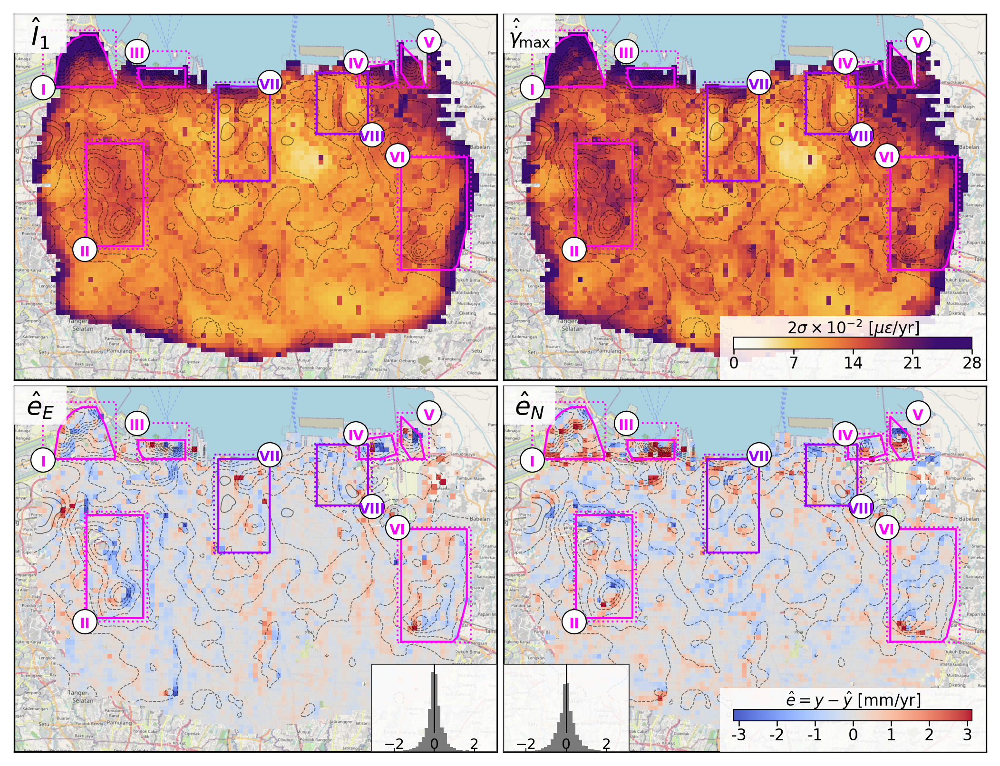

In [12]:
# ============================================================
# --- Combined uncertainty and velocity-residual figure ---
# ============================================================
# Top row: propagated 2-sigma strain-quantity uncertainties.
# Bottom row: observed minus predicted RUM velocities with histograms.

# Identify this reproducible research workflow to the public tile service.
cx.tile.USER_AGENT = (
    "JakartaStrainResearch/1.0 "
    "(+https://doi.org/10.4121/39e7a39c-d305-425f-b238-1f3a4271dda9.v3)"
)
import matplotlib.patheffects as path_effects
from matplotlib.patches import Rectangle
from matplotlib.transforms import ScaledTranslation
from shapely.geometry import MultiPoint, Polygon

OUTPUT_STEM = FIGURES_DIR / "rum_uncertainty_residual_combined_2x2"

# Residuals e_hat = y - y_hat for the area-average RUM velocities.
e_E_hat = public_df["east"].to_numpy(dtype=float) - np.asarray(archive["solution"]["y_E_hat"], dtype=float)
e_N_hat = public_df["north"].to_numpy(dtype=float) - np.asarray(archive["solution"]["y_N_hat"], dtype=float)

# Two-sigma uncertainties are read directly in microstrain/yr from the
# variances in the derived strain-rate quantity table.
two_sigma_i1 = 2.0 * np.sqrt(np.maximum(quantity_df["var_i1"].to_numpy(dtype=float), 0.0))
two_sigma_gamma = 2.0 * np.sqrt(np.maximum(quantity_df["var_gamma_max"].to_numpy(dtype=float), 0.0))
valid_mask = plot_mask & np.isfinite(two_sigma_i1) & np.isfinite(two_sigma_gamma)
x_fem = elem_centers[:, 0][valid_mask]
y_fem = elem_centers[:, 1][valid_mask]

xlim = (float(np.nanmin(E_rum) - 2000.0), float(np.nanmax(E_rum) + 2000.0))
ylim = (float(np.nanmin(N_rum) - 2000.0), float(np.nanmax(N_rum) + 2000.0))

# ============================================================
# --- Plotting helpers ---
# ============================================================


def symmetric_limit(*arrays, nsigma=5.0, fallback=1.0):
    """Return a robust symmetric plotting limit for one or more data arrays."""
    values = np.concatenate([np.ravel(np.asarray(a, dtype=float)) for a in arrays])
    values = values[np.isfinite(values)]
    if values.size == 0:
        return fallback
    vmax = nsigma * np.nanstd(values, ddof=1)
    if not np.isfinite(vmax) or vmax <= 0:
        vmax = np.nanmax(np.abs(values))
    return vmax if np.isfinite(vmax) and vmax > 0 else fallback


def colorbar_integer_ticks(vmin, vmax, n_inner=3):
    """Return colorbar positions and compact integer-formatted tick labels."""
    positions = np.linspace(vmin, vmax, n_inner + 2)
    abs_max = max(abs(vmin), abs(vmax))
    if not np.isfinite(abs_max) or abs_max == 0:
        return positions, [f"{v:.0f}" for v in positions], 0
    exponent = int(np.floor(np.log10(abs_max)))
    for _ in range(12):
        labels = np.round(positions * 10.0 ** (-exponent)).astype(int)
        if len(np.unique(labels)) == len(positions):
            break
        exponent -= 1
    labels = np.round(positions * 10.0 ** (-exponent)).astype(int)
    return positions, [str(v) for v in labels], exponent

uncertainty_cmap = LinearSegmentedColormap.from_list(
    "magma_r_manual",
    [
        (0.00, "#FCFDFB"),
        (0.10, "#F8F6E8"),
        (0.25, "#F2C649"),
        (0.40, "#F18F3B"),
        (0.55, "#D1493F"),
        (0.70, "#7A1F5C"),
        (0.85, "#3B0F70"),
        (1.00, "#3B0F70"),
    ],
)


def add_basemap(ax):
    """Add the selected web basemap beneath the plotted strain-rate data."""
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect("equal", adjustable="box")
    cx.add_basemap(
        ax,
        crs="EPSG:23830",
        source=cx.providers.OpenStreetMap.Mapnik,
        zoom=12,
        attribution=False,
        zorder=0,
    )
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


def finish_map_axis(ax):
    """Apply the shared map extent, aspect ratio, and axis formatting."""
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(left=False, bottom=False)

# Region coordinates and labels used in the manuscript.
def region_groups():
    """Return the main and additional Jakarta subsidence-region definitions."""
    return [
        (MAIN_REGIONS, MAIN_REGION_LABELS, MAIN_REGION_COLOR),
        (ADDITIONAL_REGIONS, ADDITIONAL_REGION_LABELS, ADDITIONAL_REGION_COLOR),
    ]


def draw_region_outline(ax, regions, labels, color, circle_labels=False):
    """Draw one set of region outlines and their Roman-numeral labels."""
    xr = E_rum
    yr = N_rum
    text_transform = ax.transData + ScaledTranslation(
        0.0,
        -0.5 / 25.4,
        ax.figure.dpi_scale_trans,
    )

    for label, (x1, y1, x2, y2) in zip(labels, regions):
        xmin, xmax = min(x1, x2), max(x1, x2)
        ymin, ymax = min(y1, y2), max(y1, y2)
        inside = (xr >= xmin) & (xr <= xmax) & (yr >= ymin) & (yr <= ymax)
        idx = np.nonzero(inside)[0]
        if idx.size >= 3:
            hull = MultiPoint([(xr[j], yr[j]) for j in idx]).convex_hull
            if isinstance(hull, Polygon):
                hx, hy = hull.exterior.xy
                ax.plot(hx, hy, color=color, linewidth=1.0, zorder=20)
        ax.add_patch(
            Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                fill=False,
                edgecolor=color,
                linewidth=0.9,
                linestyle=":",
                zorder=19,
            )
        )

        if circle_labels:
            if label == "I":
                tx, ty = xmin, ymin
            elif label == "V":
                tx, ty = xmax, ymax
            elif label == "II":
                tx, ty = xmin, ymin
            elif label == "VII":
                tx, ty = xmax, ymax
            elif label == "VIII":
                tx, ty = xmax, ymin
            else:
                tx, ty = xmin, ymax
            ax.scatter(
                tx,
                ty,
                s=150,
                marker="o",
                facecolor="white",
                edgecolor="black",
                linewidth=0.55,
                zorder=100,
                clip_on=False,
            )
            ax.text(
                tx,
                ty,
                label,
                color=color,
                fontsize=7.1,
                fontweight="bold",
                ha="center",
                va="center",
                transform=text_transform,
                zorder=101,
                clip_on=False,
            )
        else:
            if label == "V":
                tx, ty, ha, va = xmax, ymin, "right", "top"
            else:
                tx, ty, ha, va = xmin, ymax, "left", "bottom"
            ax.text(
                tx,
                ty,
                label,
                color=color,
                fontsize=6.6,
                fontweight="bold",
                ha=ha,
                va=va,
                zorder=21,
                path_effects=[
                    path_effects.Stroke(linewidth=0.9, foreground="black"),
                    path_effects.Normal(),
                ],
            )


def add_regions(ax):
    """Add all predefined Jakarta subsidence regions to a map axis."""
    for regions, labels, color in region_groups():
        draw_region_outline(ax, regions, labels, color, circle_labels=True)

# Clip the transversal-velocity contours to the finite-element support.
support_polygons = []
for elem, keep in zip(elements, valid_mask):
    if not keep:
        continue
    corners = node_coords[np.asarray(elem[:4], dtype=int), :2]
    poly = Polygon(corners)
    if poly.is_valid and not poly.is_empty:
        support_polygons.append(poly)
support_footprint = unary_union(support_polygons)

Xbg = np.asarray(plot_data["X"])
Ybg = np.asarray(plot_data["Y"])
Zbg = np.asarray(plot_data["mean_kriging"])
try:
    from shapely import contains_xy

    inside_support = contains_xy(
        support_footprint,
        Xbg.ravel(),
        Ybg.ravel(),
    ).reshape(Xbg.shape)
except ImportError:
    from shapely.vectorized import contains

    inside_support = contains(
        support_footprint,
        Xbg.ravel(),
        Ybg.ravel(),
    ).reshape(Xbg.shape)
Zbg_masked = np.ma.array(Zbg, mask=(~inside_support) | (~np.isfinite(Zbg)))

# ============================================================
# --- Figure layout and shared style settings ---
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(7.05, 5.50), dpi=300)
fig.subplots_adjust(left=0.025, right=0.992, bottom=0.035, top=0.975, wspace=0.012, hspace=0.018)

LEGEND_BACKGROUND_ALPHA = 0.85
LEGEND_SCALE = 1.20
LEGEND_WIDTH = 0.4598 * LEGEND_SCALE
LEGEND_HEIGHT = 0.1452 * LEGEND_SCALE
LEGEND_CBAR_WIDTH = 0.4114 * LEGEND_SCALE
LEGEND_CBAR_HEIGHT = 0.02662 * LEGEND_SCALE
LEGEND_CBAR_Y = 0.07018 * LEGEND_SCALE
LEGEND_FONT_SIZE = 6.6 * LEGEND_SCALE
LEGEND_LABELPAD = 1.4 * LEGEND_SCALE
LEGEND_TICK_LENGTH = 2.3 * LEGEND_SCALE
LEGEND_TICK_PAD = 0.7 * LEGEND_SCALE
LEGEND_TICK_WIDTH = 0.5 * LEGEND_SCALE
FIELD_SYMBOL_FONT_SIZE = 13
FIELD_SYMBOL_GAMMA_FONT_SIZE = 10.5
FIELD_SYMBOL_BOX_WIDTH = 0.108
FIELD_SYMBOL_BOX_HEIGHT = 0.105


def add_field_symbol(ax, label, fontsize=FIELD_SYMBOL_FONT_SIZE):
    """Draw a fixed-size field-label panel in the axes' upper-left corner."""
    ax.add_patch(
        Rectangle(
            (0.0, 1.0 - FIELD_SYMBOL_BOX_HEIGHT),
            FIELD_SYMBOL_BOX_WIDTH,
            FIELD_SYMBOL_BOX_HEIGHT,
            transform=ax.transAxes,
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            zorder=40,
        )
    )
    ax.text(
        0.5 * FIELD_SYMBOL_BOX_WIDTH,
        1.0 - 0.5 * FIELD_SYMBOL_BOX_HEIGHT,
        label,
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight="bold",
        zorder=41,
    )

# Draw one top-row uncertainty map.
def draw_uncertainty_panel(ax, values, show_shared_legend=False):
    """Plot one propagated uncertainty field with its map annotations."""
    add_basemap(ax)
    values_masked = np.asarray(values, dtype=float)[valid_mask]
    finite = values_masked[np.isfinite(values_masked)]
    vmax = 3.0 * 2.0 * np.nanstd(finite)
    if not np.isfinite(vmax) or vmax <= 0:
        vmax = np.nanmax(finite)
    sc = ax.scatter(
        x_fem,
        y_fem,
        c=values_masked,
        s=8.0,
        marker="s",
        cmap=uncertainty_cmap,
        vmin=0.0,
        vmax=vmax,
        linewidths=0,
        alpha=1.0,
        zorder=5,
    )
    ax.contour(
        Xbg,
        Ybg,
        Zbg_masked,
        levels=20,
        colors="black",
        alpha=0.55,
        linewidths=0.42,
        zorder=6,
    )
    add_regions(ax)

    if show_shared_legend:
        legend_width = LEGEND_WIDTH
        legend_height = LEGEND_HEIGHT
        cbar_width = LEGEND_CBAR_WIDTH
        legend_x = 1.0 - legend_width
        cbar_x = legend_x + 0.5 * (legend_width - cbar_width)
        ax.add_patch(
            Rectangle(
                (legend_x, 0.0),
                legend_width,
                legend_height,
                transform=ax.transAxes,
                facecolor="white",
                edgecolor="none",
                alpha=LEGEND_BACKGROUND_ALPHA,
                zorder=30,
            )
        )
        cax = ax.inset_axes([cbar_x, LEGEND_CBAR_Y, cbar_width, LEGEND_CBAR_HEIGHT])
        cax.set_zorder(31)
        cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
        positions, labels, _ = colorbar_integer_ticks(0.0, vmax, n_inner=3)
        cbar.set_ticks(positions)
        cbar.ax.set_xticklabels(labels)
        cbar.ax.xaxis.set_label_position("top")
        cbar.set_label(
            r"$2\sigma \times 10^{-2}$ [$\mu\epsilon$/yr]",
            fontsize=LEGEND_FONT_SIZE,
            labelpad=LEGEND_LABELPAD,
        )
        cbar.ax.tick_params(
            axis="x",
            labelsize=LEGEND_FONT_SIZE,
            length=LEGEND_TICK_LENGTH,
            pad=LEGEND_TICK_PAD,
            width=LEGEND_TICK_WIDTH,
        )
        cbar.outline.set_linewidth(0.5)
    finish_map_axis(ax)

draw_uncertainty_panel(axes[0, 0], two_sigma_i1)
draw_uncertainty_panel(axes[0, 1], two_sigma_gamma, show_shared_legend=True)

# Draw the East and North residual maps using one common colour range and
# identical histogram bins.
res_vlim = symmetric_limit(e_E_hat, e_N_hat, nsigma=5.0)
hist_xlim = (-res_vlim, res_vlim)
hist_bins = np.linspace(hist_xlim[0], hist_xlim[1], 41)
counts_E, _ = np.histogram(e_E_hat[np.isfinite(e_E_hat)], bins=hist_bins)
counts_N, _ = np.histogram(e_N_hat[np.isfinite(e_N_hat)], bins=hist_bins)
hist_ymax = 1.1 * max(counts_E.max(), counts_N.max(), 1)

residual_specs = [
    (axes[1, 0], e_E_hat, "lower right"),
    (axes[1, 1], e_N_hat, "lower left"),
]
hist_axes = []
for ax, values, hist_loc in residual_specs:
    add_basemap(ax)
    sc_res = ax.scatter(
        E_rum,
        N_rum,
        c=values,
        s=8.0,
        marker="s",
        cmap="coolwarm",
        vmin=-res_vlim,
        vmax=res_vlim,
        linewidths=0,
        alpha=0.92,
        zorder=10,
    )
    ax.contour(
        Xbg,
        Ybg,
        Zbg_masked,
        levels=20,
        colors="black",
        alpha=0.55,
        linewidths=0.42,
        zorder=11,
    )
    add_regions(ax)
    finish_map_axis(ax)

    hist_ax = inset_axes(
        ax,
        width="26%",
        height="24%",
        loc=hist_loc,
        borderpad=0.0,
    )
    hist_ax.set_facecolor((1.0, 1.0, 1.0, LEGEND_BACKGROUND_ALPHA))
    hist_ax.hist(
        values[np.isfinite(values)],
        bins=hist_bins,
        color="0.48",
        alpha=1.0,
        zorder=2,
    )
    zero_line = hist_ax.axvline(0.0, color="k", linewidth=0.65, zorder=3)
    hist_ax.set_xlim(hist_xlim)
    hist_ax.set_ylim(0, hist_ymax)
    hist_ax.set_yticks([])
    hist_ax.set_xticks([-2.0, 0.0, 2.0])
    hist_ax.set_ylabel("")
    hist_ax.set_xlabel("")
    hist_ax.tick_params(axis="y", which="both", left=False, right=False, labelleft=False)
    hist_ax.tick_params(
        axis="x",
        which="both",
        bottom=True,
        top=False,
        labelbottom=True,
        direction="in",
        length=2.0,
        width=0.45,
        labelsize=7.2,
        pad=-7.0,
    )
    for spine in hist_ax.spines.values():
        spine.set_linewidth(0.5)
        spine.set_color("0.25")
    hist_ax._residual_zero_line = zero_line
    hist_ax.xaxis.set_zorder(10)
    for label in hist_ax.get_xticklabels():
        label.set_zorder(20)
        label.set_clip_on(True)
    hist_axes.append(hist_ax)

# Add one shared residual colour bar to the North-component panel.
north_ax = axes[1, 1]
north_ax.add_patch(
    Rectangle(
        (1.0 - LEGEND_WIDTH, 0.0),
        LEGEND_WIDTH,
        LEGEND_HEIGHT,
        transform=north_ax.transAxes,
        facecolor="white",
        edgecolor="none",
        linewidth=0.0,
        alpha=LEGEND_BACKGROUND_ALPHA,
        zorder=30,
    )
)
res_legend_width = LEGEND_WIDTH
res_cbar_width = LEGEND_CBAR_WIDTH
res_cbar_x = 1.0 - res_legend_width + 0.5 * (res_legend_width - res_cbar_width)
res_cax = north_ax.inset_axes([res_cbar_x, LEGEND_CBAR_Y, res_cbar_width, LEGEND_CBAR_HEIGHT])
res_cax.set_zorder(31)
res_cbar = fig.colorbar(sc_res, cax=res_cax, orientation="horizontal")
res_ticks = np.arange(np.ceil(-res_vlim), np.floor(res_vlim) + 1.0, 1.0)
res_cbar.set_ticks(res_ticks)
res_cbar.ax.set_xticklabels([f"{tick:g}" for tick in res_ticks])
res_cbar.ax.xaxis.set_label_position("top")
res_cbar.set_label(
    r"$\hat{e} = y - \hat{y}$ [mm/yr]",
    fontsize=LEGEND_FONT_SIZE,
    labelpad=LEGEND_LABELPAD,
)
res_cbar.ax.tick_params(
    axis="x",
    labelsize=LEGEND_FONT_SIZE,
    length=LEGEND_TICK_LENGTH,
    pad=LEGEND_TICK_PAD,
    width=LEGEND_TICK_WIDTH,
)
res_cbar.outline.set_linewidth(0.5)

# Stop x=0 lines 1 mm above the in-axis zero labels.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
gap_px = fig.dpi / 25.4
for hist_ax in hist_axes:
    zero_label = next(
        label
        for tick, label in zip(hist_ax.get_xticks(), hist_ax.get_xticklabels())
        if np.isclose(tick, 0.0)
    )
    label_top_px = zero_label.get_window_extent(renderer=renderer).y1
    line_start = hist_ax.transAxes.inverted().transform((0.0, label_top_px + gap_px))[1]
    hist_ax._residual_zero_line.set_ydata([np.clip(line_start, 0.0, 0.95), 1.0])

# Field labels use the same white-box construction as the top-view panels in
# fig_ideal_bowl_jgr, with the box edge anchored exactly at the axes corner.
add_field_symbol(axes[0, 0], r"$\hat{I}_1$")
add_field_symbol(
    axes[0, 1],
    r"$\hat{\dot{\gamma}}_{\!\max}$",
    fontsize=FIELD_SYMBOL_GAMMA_FONT_SIZE,
)
add_field_symbol(axes[1, 0], r"$\hat{e}_E$")
add_field_symbol(axes[1, 1], r"$\hat{e}_N$")

# Save both a high-resolution raster figure and a vector PDF.
for suffix in (".png", ".pdf"):
    path = OUTPUT_STEM.with_suffix(suffix)
    kwargs = {"bbox_inches": "tight", "pad_inches": 0.02}
    if suffix == ".png":
        kwargs["dpi"] = 500
    fig.savefig(path, **kwargs)
    print(f"Saved {path}")

print(f"Uncertainty maxima: I1={6*np.nanstd(two_sigma_i1[valid_mask]):.6f}, gamma={6*np.nanstd(two_sigma_gamma[valid_mask]):.6f}")
print(f"Residual color limit: +/-{res_vlim:.3f} mm/yr")

# ============================================================
# --- Numerical values reported with the figure ---
# ============================================================
# Manuscript statistics use the same RUM-supported FEM fields and propagated
# uncertainties as the maps above.  Convert estimates and sigmas together so
# every significance comparison is made in microstrain/yr.
i1_estimate_micro = quantity_df["i1"].to_numpy(dtype=float)
i1_sigma_micro = np.sqrt(np.maximum(quantity_df["var_i1"].to_numpy(dtype=float), 0.0))
gamma_estimate_micro = quantity_df["gamma_max"].to_numpy(dtype=float)
gamma_sigma_micro = np.sqrt(np.maximum(quantity_df["var_gamma_max"].to_numpy(dtype=float), 0.0))

i1_valid = plot_mask & np.isfinite(i1_estimate_micro) & np.isfinite(i1_sigma_micro)
gamma_valid = plot_mask & np.isfinite(gamma_estimate_micro) & np.isfinite(gamma_sigma_micro)
i1_exceeds_2sigma = i1_valid & (np.abs(i1_estimate_micro) > 2.0 * i1_sigma_micro)
gamma_exceeds_2sigma = gamma_valid & (np.abs(gamma_estimate_micro) > 2.0 * gamma_sigma_micro)

n_i1_valid = int(np.count_nonzero(i1_valid))
n_i1_exceeds = int(np.count_nonzero(i1_exceeds_2sigma))
n_gamma_valid = int(np.count_nonzero(gamma_valid))
n_gamma_exceeds = int(np.count_nonzero(gamma_exceeds_2sigma))
i1_exceeds_pct = 100.0 * n_i1_exceeds / n_i1_valid if n_i1_valid else np.nan
gamma_exceeds_pct = 100.0 * n_gamma_exceeds / n_gamma_valid if n_gamma_valid else np.nan

res_e_finite = e_E_hat[np.isfinite(e_E_hat)]
res_n_finite = e_N_hat[np.isfinite(e_N_hat)]
rmse_e = float(np.sqrt(np.mean(res_e_finite**2))) if res_e_finite.size else np.nan
rmse_n = float(np.sqrt(np.mean(res_n_finite**2))) if res_n_finite.size else np.nan

print("\n=== Manuscript numerical summary ===")
print(
    f"I1: {n_i1_exceeds}/{n_i1_valid} valid RUM-supported estimates exceed 2 sigma "
    f"({i1_exceeds_pct:.1f}%)."
)
print(
    f"gamma_max: {n_gamma_exceeds}/{n_gamma_valid} valid RUM-supported estimates exceed 2 sigma "
    f"({gamma_exceeds_pct:.1f}%)."
)
print(f"East residual RMSE (N={res_e_finite.size}): {rmse_e:.2f} mm/yr.")
print(f"North residual RMSE (N={res_n_finite.size}): {rmse_n:.2f} mm/yr.")

#manuscript_paragraph = rf"""The propagated uncertainties of $\hat{{I}}_1$ and $\widehat{{\dot{{\gamma}}}}_{{\max}}$ are lowest over the interior of the finite-element mesh and increase toward its boundaries. Approximately {i1_exceeds_pct:.1f}\% and {gamma_exceeds_pct:.1f}\% of the estimated RUMs exceed the $2\sigma$ uncertainty threshold for $\hat{{I}}_1$ and $\widehat{{\dot{{\gamma}}}}_{{\max}}$, respectively. Residuals between the observed RUM velocities and their corresponding area-averaged finite-element predictions are centered close to zero, with RMS values of {rmse_e:.2f} mm/yr and {rmse_n:.2f} mm/yr for the east and north components, respectively. The clearest spatially coherent residual structure occurs in region III."""

# Display the completed figure as a notebook output.
display(fig)
plt.close(fig)


## Main subsidence-region outlines used in the Jakarta strain maps

In [13]:
def plot_regions_with_strain_summary(ax, E_rum, N_rum,
                                     eps_1_hat, eps_2_hat, I1_hat, gamma_max_hat,
                                     strain_type="areal",
                                     regions_proj=None,
                                     label_offset=0,
                                     color=MAIN_REGION_COLOR,
                                     include_additional_regions=False):
    """
    Plot the predefined deformation regions and print their strain summaries.

    Main Regions I-VI are always included. Regions VII-VIII are added when
    ``include_additional_regions`` is true. All regions use a solid convex hull,
    a dotted rectangular boundary, and circular Roman-numeral labels.

    Returns
    -------
    df_summary_strain, df_summary_principal
        Regional summaries printed by the main map cell.
    """

    from shapely.geometry import MultiPoint, Polygon, box
    from datetime import datetime

    if strain_type not in {"areal", "max_shear"}:
        raise ValueError("strain_type must be 'areal' or 'max_shear'.")

    if regions_proj is None:
        regions_proj = MAIN_REGIONS.copy()

    roman_labels = MAIN_REGION_LABELS.copy()
    additional_color = ADDITIONAL_REGION_COLOR

    # Shared outline style for all regions.
    hull_linewidth = 1.6
    rect_linewidth = 1.4
    hull_zorder = 10
    rect_zorder = 9

    # ------------------------------------------------------------
    # Roman-numeral label style.
    # ------------------------------------------------------------
    label_circle_size = 420
    label_circle_linewidth = 0.8
    label_circle_facecolor = "white"
    label_circle_edgecolor = "black"

    label_fontsize = 12 * 0.90

    # Keep circles and numerals above the map and strain glyphs.
    label_circle_zorder = 100
    label_text_zorder = 101

    # Move numerals slightly downward for visual centering
    # inside the circles in display space (mm on the page/screen).
    text_down_mm = 0.5
    text_centering_transform = ax.transData + ScaledTranslation(
        0, -text_down_mm / 25.4, ax.figure.dpi_scale_trans
    )

    # ------------------------------------------------------------
    # Merge regions and keep region groups for plotting + summaries
    # ------------------------------------------------------------
    all_regions = regions_proj.copy()
    all_labels = roman_labels.copy()
    all_groups = ["main"] * len(regions_proj)

    if include_additional_regions:
        all_regions += ADDITIONAL_REGIONS
        all_labels += ADDITIONAL_REGION_LABELS
        all_groups += ["additional"] * len(ADDITIONAL_REGIONS)

    xr, yr = np.asarray(E_rum), np.asarray(N_rum)
    eps_1_hat, eps_2_hat = np.asarray(eps_1_hat), np.asarray(eps_2_hat)
    dil = np.asarray(I1_hat)
    gamma_max_hat = np.asarray(gamma_max_hat)

    summary_strain = []
    summary_principal = []

    # ------------------------------------------------------------
    # REGION LOOP
    # ------------------------------------------------------------
    for label, region_group, (x1, y1, x2, y2) in zip(all_labels, all_groups, all_regions):
        xmin, xmax = min(x1, x2), max(x1, x2)
        ymin, ymax = min(y1, y2), max(y1, y2)

        inside = (xr >= xmin) & (xr <= xmax) & (yr >= ymin) & (yr <= ymax)
        idx = np.nonzero(inside)[0]

        region_dict = {
            "region_id": label,
            "region_group": region_group,
            "n_points": int(idx.size),
        }

        principal_dict = {
            "region_id": label,
            "region_group": region_group,
        }

        # --------------------------------------------------------
        # STRAIN SUMMARY
        # --------------------------------------------------------
        if idx.size > 0:
            if strain_type == "areal":
                vals = dil[idx]
                min_idx, max_idx = idx[np.nanargmin(vals)], idx[np.nanargmax(vals)]
                region_dict.update({
                    "RUM_index_max_compression": int(min_idx),
                    "max_compression_value": round(dil[min_idx], 1),
                    "RUM_index_max_dilation": int(max_idx),
                    "max_dilation_value": round(dil[max_idx], 1),
                })

            elif strain_type == "max_shear":
                vals = gamma_max_hat[idx]
                min_idx, max_idx = idx[np.nanargmin(vals)], idx[np.nanargmax(vals)]
                region_dict.update({
                    "RUM_index_min_tau": int(min_idx),
                    "min_tau_value": round(gamma_max_hat[min_idx], 1),
                    "RUM_index_max_tau": int(max_idx),
                    "max_tau_value": round(gamma_max_hat[max_idx], 1),
                })

            # ----------------------------------------------------
            # PRINCIPAL STRAINS
            # ----------------------------------------------------
            e1_vals, e2_vals = eps_1_hat[idx], eps_2_hat[idx]

            max_e1_idx = idx[np.nanargmax(e1_vals)]
            min_e1_idx = idx[np.nanargmin(e1_vals)]
            max_e2_idx = idx[np.nanargmax(e2_vals)]
            min_e2_idx = idx[np.nanargmin(e2_vals)]

            principal_dict.update({
                "RUM_index_max_lambda1": int(max_e1_idx),
                "max_lambda1": round(eps_1_hat[max_e1_idx], 1),
                "lambda2_at_max_lambda1": round(eps_2_hat[max_e1_idx], 1),
                "RUM_index_min_lambda1": int(min_e1_idx),
                "min_lambda1": round(eps_1_hat[min_e1_idx], 1),
                "lambda2_at_min_lambda1": round(eps_2_hat[min_e1_idx], 1),
                "RUM_index_max_lambda2": int(max_e2_idx),
                "max_lambda2": round(eps_2_hat[max_e2_idx], 1),
                "lambda1_at_max_lambda2": round(eps_1_hat[max_e2_idx], 1),
                "RUM_index_min_lambda2": int(min_e2_idx),
                "min_lambda2": round(eps_2_hat[min_e2_idx], 1),
                "lambda1_at_min_lambda2": round(eps_1_hat[min_e2_idx], 1),
            })

        summary_strain.append(region_dict)
        summary_principal.append(principal_dict)

        # --------------------------------------------------------
        # PLOT OUTLINES
        # --------------------------------------------------------
        if region_group == "additional":
            plot_color = additional_color
        else:
            plot_color = color

        # Solid convex hull around the actual included points/cells.
        # The same style is used for all regions.
        if idx.size >= 3:
            pts = [(xr[j], yr[j]) for j in idx]
            hull = MultiPoint(pts).convex_hull

            if isinstance(hull, Polygon):
                hx, hy = hull.exterior.xy
                ax.plot(
                    hx,
                    hy,
                    linestyle="-",
                    linewidth=hull_linewidth,
                    color=plot_color,
                    zorder=hull_zorder,
                )

        elif idx.size == 2:
            ax.plot(
                [xr[idx[0]], xr[idx[1]]],
                [yr[idx[0]], yr[idx[1]]],
                linestyle="-",
                linewidth=1.0,
                color=plot_color,
                zorder=hull_zorder,
            )

        elif idx.size == 1:
            ax.plot(
                xr[idx[0]],
                yr[idx[0]],
                marker="o",
                markersize=6,
                color=plot_color,
                zorder=hull_zorder + 1,
            )

        # Dotted rectangle around the predefined region bounds.
        # The same rectangular style is used for all regions.
        rect = box(xmin, ymin, xmax, ymax)
        rx, ry = rect.exterior.xy
        ax.plot(
            rx,
            ry,
            linestyle=":",
            linewidth=rect_linewidth,
            color=plot_color,
            zorder=rect_zorder,
        )

        # --------------------------------------------------------
        # Roman numeral labels with white circular background
        # --------------------------------------------------------

        # V: top-right corner.
        if label == "V":
            label_x = xmax
            label_y = ymax + label_offset

        # II: lower-left corner, positioned like V directly on the box corner.
        elif label == "II":
            label_x = xmin
            label_y = ymin + label_offset

        # VII: upper-right corner, positioned directly on the box corner.
        elif label == "VII":
            label_x = xmax
            label_y = ymax + label_offset

        # VIII: lower-right corner, positioned directly on the box corner.
        elif label == "VIII":
            label_x = xmax
            label_y = ymin + label_offset

        else:
            label_x = xmin
            label_y = ymax + label_offset

        # Perfect white circle in screen/display space.
        # High z-order keeps the bullet above glyphs, outlines, contours, etc.
        ax.scatter(
            label_x,
            label_y,
            s=label_circle_size,
            marker="o",
            facecolor=label_circle_facecolor,
            edgecolor=label_circle_edgecolor,
            linewidth=label_circle_linewidth,
            zorder=label_circle_zorder,
            clip_on=False,
        )

        # Roman numeral visually centered inside the circle.
        ax.text(
            label_x,
            label_y,
            label,
            color=plot_color,
            fontsize=label_fontsize,
            fontweight="bold",
            ha="center",
            va="center",
            transform=text_centering_transform,
            zorder=label_text_zorder,
            clip_on=False,
        )

    # --------------------------------------------------------
    # DATAFRAMES
    # --------------------------------------------------------
    df_summary_strain = pd.DataFrame(summary_strain)
    df_summary_principal = pd.DataFrame(summary_principal)

    print(f"\n--- {strain_type.capitalize()} Summary ---")
    print(df_summary_strain.to_string(index=False))

    print("\n--- Principal Strain Summary ---")
    print(df_summary_principal.to_string(index=False))

    # --------------------------------------------------------
    # CUMULATIVE STRAIN SUMMARY
    # --------------------------------------------------------
    start_date = datetime(2014, 10, 1)
    end_date = datetime(2025, 6, 30)
    n_years = (end_date - start_date).days / 365.25

    print(f"\nn_year: {n_years}")

    df_cumulative = []

    for label, region_group, (x1, y1, x2, y2) in zip(all_labels, all_groups, all_regions):
        xmin, xmax = min(x1, x2), max(x1, x2)
        ymin, ymax = min(y1, y2), max(y1, y2)

        inside = (xr >= xmin) & (xr <= xmax) & (yr >= ymin) & (yr <= ymax)
        idx = np.nonzero(inside)[0]

        if idx.size > 0:
            cum_e1 = eps_1_hat[idx] * n_years
            cum_e2 = eps_2_hat[idx] * n_years

            row = {
                "region_id": label,
                "region_group": region_group,
                "n_points": int(idx.size),
                "min_e1": round(np.nanmin(cum_e1), 1),
                "max_e1": round(np.nanmax(cum_e1), 1),
                "min_e2": round(np.nanmin(cum_e2), 1),
                "max_e2": round(np.nanmax(cum_e2), 1),
            }

            if strain_type == "areal":
                cum_I1 = dil[idx] * n_years
                row["min_I1"] = round(np.nanmin(cum_I1), 1)
                row["max_I1"] = round(np.nanmax(cum_I1), 1)

            elif strain_type == "max_shear":
                cum_tau = gamma_max_hat[idx] * n_years
                row["min_tau"] = round(np.nanmin(cum_tau), 1)
                row["max_tau"] = round(np.nanmax(cum_tau), 1)

        else:
            row = {
                "region_id": label,
                "region_group": region_group,
                "n_points": 0,
            }

        df_cumulative.append(row)

    df_cumulative = pd.DataFrame(df_cumulative)

    print("\n--- Cumulative Strain Summary ---")
    print(df_cumulative.to_string(index=False))

    return df_summary_strain, df_summary_principal


## Main strain-rate quantity maps over Jakarta

The next cell defines the reusable map functions. In the final cell, select:

- `strain_type = "areal"` and `color_mode = "field_2sigma"` to produce the map of $\hat{I}_1$;
- `strain_type = "max_shear"`,`color_mode = "piecewise_log"` and `glyphs_on = False` to produce the map of $\hat{\dot{\gamma}}_{\max}$.

Run the final cell once for each selection to save both manuscript figures.


In [14]:
## This block contains the functions needed in order to create the maps ##
from matplotlib.patches import FancyArrow, Rectangle, Polygon as MplPolygon, FancyArrowPatch

try:
    from shapely import contains_xy as _contains_xy_raw

    def _contains_xy(geom, x, y):
        """Return whether the supplied coordinates fall inside the geometry."""
        return _contains_xy_raw(geom, x, y)

except Exception:
    from shapely.vectorized import contains as _contains_xy_raw

    def _contains_xy(geom, x, y):
        """Return whether the supplied coordinates fall inside the geometry."""
        return _contains_xy_raw(geom, x, y)

INSET_TEXT_FONTSIZE = 8.0
INSET_REF_SIZE = 0.24
# =================================================
# Helper: integer-looking colorbar labels without extending limits
# =================================================
def colorbar_integer_ticks(vmin, vmax, n_inner=3):
    """
    Create colorbar ticks with:
      min, n_inner interior values, max

    Tick positions are always inside the true color limits [vmin, vmax],
    which avoids white gaps/slivers at the colorbar ends.

    Labels are displayed as integer-like scaled values. The exponent is refined
    until the labels are unique.
    """

    n_ticks = n_inner + 2
    tick_positions = np.linspace(vmin, vmax, n_ticks)

    abs_max = max(abs(vmin), abs(vmax))

    if not np.isfinite(abs_max) or abs_max == 0:
        tick_labels = [f"{v:.0f}" for v in tick_positions]
        return tick_positions, tick_labels, 0

    exponent = int(np.floor(np.log10(abs_max)))

    for _ in range(12):
        scale_factor = 10.0 ** (-exponent)
        scaled_ticks = tick_positions * scale_factor
        tick_labels_int = np.round(scaled_ticks).astype(int)

        if len(np.unique(tick_labels_int)) == n_ticks:
            break

        exponent -= 1

    scale_factor = 10.0 ** (-exponent)
    scaled_ticks = tick_positions * scale_factor
    tick_labels_int = np.round(scaled_ticks).astype(int)

    tick_labels = [str(v) for v in tick_labels_int]

    return tick_positions, tick_labels, exponent

# =================================================
# Helper: contour clipping to FEM/RUM plotting support
# =================================================
def build_fem_element_polygons(elements, node_coords):
    """
    Build FEM element polygons from the first four Q8 corner nodes.

    The original strain map displays each FEM value as a square marker at the
    element center. For clipping the contour field, however, we need an actual
    polygon footprint of the same elements.
    """
    polygons = []

    for elem in elements:
        corners = node_coords[np.asarray(elem[:4], dtype=int), :2]

        if not np.all(np.isfinite(corners)):
            polygons.append(None)
            continue

        poly = ShapelyPolygon(corners)

        if poly.is_empty or not poly.is_valid:
            polygons.append(None)
        else:
            polygons.append(poly)

    return np.asarray(polygons, dtype=object)


def build_fem_support_footprint(
    elements,
    node_coords,
    support_mask,
    buffer_m=0.0,
    simplify_m=0.0,
):
    """
    Build the contour-support footprint from the plotted FEM cells.

    support_mask should usually be the final valid_mask. If plot_mask was
    created from the RUM-envelope cell before this plotting script, valid_mask
    already represents the RUM-supported FEM footprint, with empty numerical
    cells removed.

    buffer_m:
      Expands or contracts the contour-support polygon in projected meters.
      Use 0.0 to clip exactly to the selected FEM-cell footprint.
      A small positive value can close tiny cracks between neighboring cells.
      A negative value clips slightly inside the footprint.

    simplify_m:
      Simplifies the support polygon boundary in projected meters.
      Use 0.0 to preserve the exact cell-stepped boundary.
      A small positive value reduces boundary complexity and can speed up
      point-in-polygon masking, but large values will smooth away details.
    """
    support_mask = np.asarray(support_mask, dtype=bool)

    if support_mask.shape[0] != len(elements):
        raise ValueError(
            f"support_mask must have length {len(elements)}, got {support_mask.shape[0]}."
        )

    fem_polygons = build_fem_element_polygons(elements, node_coords)

    support_polygons = [
        poly
        for poly, keep in zip(fem_polygons, support_mask)
        if keep and poly is not None and (not poly.is_empty)
    ]

    if len(support_polygons) == 0:
        raise ValueError("No FEM polygons available for contour support footprint.")

    footprint = unary_union(support_polygons)

    if buffer_m != 0:
        footprint = footprint.buffer(buffer_m)

    if simplify_m > 0:
        footprint = footprint.simplify(simplify_m, preserve_topology=True)

    return footprint


def mask_contour_grid_to_footprint(X, Y, Z, footprint):
    """
    Mask kriging-grid values outside the FEM/RUM support footprint.

    Matplotlib contour respects masked arrays. By masking Z outside the
    selected FEM support, contour lines are cut at the same boundary as the
    plotted deformation field instead of extending over unsupported areas.
    """
    X = np.asarray(X)
    Y = np.asarray(Y)
    Z = np.asarray(Z)

    if X.shape != Y.shape or X.shape != Z.shape:
        raise ValueError(
            "plot_data['X'], plot_data['Y'], and plot_data['mean_kriging'] "
            "must have the same shape."
        )

    inside = _contains_xy(
        footprint,
        X.ravel(),
        Y.ravel(),
    ).reshape(X.shape)

    contour_mask = (~inside) | (~np.isfinite(Z))

    return np.ma.array(Z, mask=contour_mask), inside

# =================================================
# Helper: explanatory strain-type inset
# =================================================
def _get_cmap_object(cmap_like):
    """Return a matplotlib colormap object from a colormap name or object."""
    if hasattr(cmap_like, "__call__"):
        return cmap_like
    return plt.get_cmap(cmap_like)


def draw_square(
    ax_inset,
    center,
    size,
    facecolor,
    edgecolor="black",
    linewidth=0.35,
    alpha=1.0,
    linestyle="-",
    zorder=3,
):
    """Draw a true square in inset data coordinates."""
    x, y = center
    patch = Rectangle(
        (x - size / 2.0, y - size / 2.0),
        size,
        size,
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        alpha=alpha,
        linestyle=linestyle,
        zorder=zorder,
    )
    ax_inset.add_patch(patch)
    return patch


def draw_parallelogram(
    ax_inset,
    center,
    size,
    skew,
    facecolor,
    edgecolor="black",
    linewidth=0.35,
    alpha=1.0,
    linestyle="-",
    zorder=3,
):
    """
    Draw a compact sheared quadrilateral in inset data coordinates.

    The vertical height equals the reference square size, so the visual area is
    comparable to the undeformed FEM cell.
    """
    x, y = center
    half = size / 2.0

    pts = np.array([
        [x - half + skew, y - half],
        [x + half + skew, y - half],
        [x + half - skew, y + half],
        [x - half - skew, y + half],
    ])

    patch = MplPolygon(
        pts,
        closed=True,
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        alpha=alpha,
        linestyle=linestyle,
        zorder=zorder,
    )
    ax_inset.add_patch(patch)
    return patch


def draw_dashed_reference(
    ax_inset,
    center,
    size,
    edgecolor="0.65",
    linewidth=0.8,
    zorder=2,
):
    """Draw the original FEM footprint as a light dashed square."""
    return draw_square(
        ax_inset,
        center=center,
        size=size,
        facecolor="none",
        edgecolor=edgecolor,
        linewidth=linewidth,
        alpha=1.0,
        linestyle="--",
        zorder=zorder,
    )


def draw_arrow(
    ax_inset,
    start,
    end,
    color="black",
    linewidth=0.35,
    mutation_scale=6,
    zorder=4,
):
    """Draw a compact arrow in inset data coordinates."""
    arrow = FancyArrowPatch(
        start,
        end,
        arrowstyle="-|>",
        mutation_scale=mutation_scale,
        linewidth=linewidth,
        color=color,
        zorder=zorder,
    )
    ax_inset.add_patch(arrow)
    return arrow


def draw_contraction_arrows(
    ax_inset,
    center,
    horizontal_outer=0.22,
    horizontal_inner=0.12,
    vertical_outer=None,
    vertical_inner=None,
    reference_size=INSET_REF_SIZE,
    linewidth=0.35,
    mutation_scale=5.5,
):
    """Draw inward arrows whose heads touch the dashed reference square."""
    x, y = center

    if vertical_outer is None:
        vertical_outer = reference_size / 2.0 + 0.10

    if vertical_inner is None:
        vertical_inner = reference_size / 2.0

    draw_arrow(ax_inset, (x - horizontal_outer, y), (x - horizontal_inner, y),
               linewidth=linewidth, mutation_scale=mutation_scale)
    draw_arrow(ax_inset, (x + horizontal_outer, y), (x + horizontal_inner, y),
               linewidth=linewidth, mutation_scale=mutation_scale)

    # Heads touch the dashed reference square's top and bottom edges.
    draw_arrow(ax_inset, (x, y + vertical_outer), (x, y + vertical_inner),
               linewidth=linewidth, mutation_scale=mutation_scale)
    draw_arrow(ax_inset, (x, y - vertical_outer), (x, y - vertical_inner),
               linewidth=linewidth, mutation_scale=mutation_scale)


def draw_dilatation_arrows(
    ax_inset,
    center,
    horizontal_inner=0.15,
    horizontal_outer=0.28,
    vertical_inner=0.15,
    vertical_outer=0.28,
    linewidth=0.35,
    mutation_scale=5.5,
):
    """Draw outward arrows matching the I1 dilatation style."""
    x, y = center

    draw_arrow(ax_inset, (x - horizontal_inner, y), (x - horizontal_outer, y),
               linewidth=linewidth, mutation_scale=mutation_scale)
    draw_arrow(ax_inset, (x + horizontal_inner, y), (x + horizontal_outer, y),
               linewidth=linewidth, mutation_scale=mutation_scale)
    draw_arrow(ax_inset, (x, y + vertical_inner), (x, y + vertical_outer),
               linewidth=linewidth, mutation_scale=mutation_scale)
    draw_arrow(ax_inset, (x, y - vertical_inner), (x, y - vertical_outer),
               linewidth=linewidth, mutation_scale=mutation_scale)


def _draw_inset_label(ax_inset, x, y, text, fontsize=6.5, weight="normal", ha="center"):
    """Place one consistently styled label in an explanatory inset."""
    ax_inset.text(
        x,
        y,
        text,
        fontsize=fontsize,
        fontweight=weight,
        ha=ha,
        va="center",
        color="black",
        zorder=5,
    )


def _inset_width(ax_inset):
    """Return the current explanatory-inset width in data coordinates."""
    x0, x1 = ax_inset.get_xlim()
    return x1 - x0


def draw_i1_inset(ax_inset, cmap, fontsize=INSET_TEXT_FONTSIZE):
    """
    First-invariant inset.

    All reference FEM squares use INSET_REF_SIZE so inset symbols remain
    consistent between the areal and maximum-shear maps.
    """
    cmap = _get_cmap_object(cmap)
    neg_color = cmap(0.1)
    pos_color = cmap(0.9)

    W = _inset_width(ax_inset)

    ref_size = INSET_REF_SIZE
    comp_size = ref_size * (300.0 / 450.0)
    dil_size = ref_size * (550.0 / 450.0)
    y_shape = 0.69

    x_comp = 0.18 * W
    x_ref = 0.50 * W
    x_dil = 0.82 * W

    _draw_inset_label(
        ax_inset,
        0.50 * W,
        1.05,
        "First invariant",
        fontsize=fontsize,
        weight="bold",
    )

    draw_dashed_reference(ax_inset, center=(x_comp, y_shape), size=ref_size)
    draw_square(
        ax_inset,
        center=(x_comp, y_shape),
        size=comp_size,
        facecolor=neg_color,
        edgecolor="black",
    )
    draw_contraction_arrows(
        ax_inset,
        center=(x_comp, y_shape),
        horizontal_outer=0.21,
        horizontal_inner=0.12,
        reference_size=ref_size,
    )

    _draw_inset_label(ax_inset, x_comp, 0.38, r"$I_1 < 0$", fontsize=fontsize)
    _draw_inset_label(ax_inset, x_comp, 0.15, "Compression", fontsize=fontsize)

    draw_square(
        ax_inset,
        center=(x_ref, y_shape),
        size=ref_size,
        facecolor="white",
        edgecolor="black",
    )

    _draw_inset_label(ax_inset, x_ref, 0.38, r"$I_1 = 0$", fontsize=fontsize)
    _draw_inset_label(ax_inset, x_ref, 0.15, "No area change", fontsize=fontsize)

    draw_square(
        ax_inset,
        center=(x_dil, y_shape),
        size=dil_size,
        facecolor=pos_color,
        edgecolor="black",
    )
    draw_dashed_reference(ax_inset, center=(x_dil, y_shape), size=ref_size, zorder=4)
    draw_dilatation_arrows(
        ax_inset,
        center=(x_dil, y_shape),
        horizontal_inner=0.16,
        horizontal_outer=0.28,
        vertical_inner=0.16,
        vertical_outer=0.28,
    )

    _draw_inset_label(ax_inset, x_dil, 0.38, r"$I_1 > 0$", fontsize=fontsize)
    _draw_inset_label(ax_inset, x_dil, 0.15, "Dilatation", fontsize=fontsize)


def draw_max_shear_inset(
    ax_inset,
    cmap,
    label_gamma_max=None,
    fontsize=INSET_TEXT_FONTSIZE,
):
    r"""
    Maximum-shear inset.

    Parameters
    ----------
    ax_inset : matplotlib axes
        Inset axes where the explanatory sketch is drawn.
    cmap : str or matplotlib colormap
        Colormap used to color the deformed symbol.
    label_shear : str, optional
        LaTeX label for the plotted shear quantity.
        Expected examples:
            r"$\dot{\gamma}_{\max}$"
            r"$\dot{\gamma}_{\max}/2$"
        If None, defaults to engineering shear r"$\hat{\dot{\gamma}}_{\max}$".
    fontsize : float
        Inset text fontsize.

    Notes
    -----
    The undeformed square uses INSET_REF_SIZE, matching the first-invariant reference square size.
    """
    if label_gamma_max is None:
        label_gamma_max = r"$\hat{\dot{\gamma}}_{\max}$"

    # Remove surrounding math delimiters so we can build expressions such as
    # "$\dot{\gamma}_{\max}/2=0$" without nested dollar signs.
    label_gamma_max_inner = label_gamma_max.strip("$")

    cmap = _get_cmap_object(cmap)
    shear_color = cmap(0.75)

    W = _inset_width(ax_inset)

    ref_size = INSET_REF_SIZE
    y_shape = 0.69

    x_ref = 0.32 * W
    x_shear = 0.68 * W

    _draw_inset_label(
        ax_inset,
        0.50 * W,
        1.05,
        "Maximum shear",
        fontsize=fontsize,
        weight="bold",
    )

    # Reference / no-gamma_max_hat state.
    draw_square(
        ax_inset,
        center=(x_ref, y_shape),
        size=ref_size,
        facecolor="white",
        edgecolor="black",
    )

    _draw_inset_label(
        ax_inset,
        x_ref,
        0.38,
        rf"${label_gamma_max_inner}=0$",
        fontsize=fontsize,
    )

    # Sheared / distortional state.
    draw_dashed_reference(
        ax_inset,
        center=(x_shear, y_shape),
        size=ref_size,
    )

    draw_parallelogram(
        ax_inset,
        center=(x_shear, y_shape),
        size=ref_size,
        skew=-0.075,
        facecolor=shear_color,
        edgecolor="black",
        alpha=0.8,
    )

    draw_arrow(
        ax_inset,
        (x_shear - 0.12, y_shape + ref_size / 2.0 + 0.065),
        (x_shear + 0.14, y_shape + ref_size / 2.0 + 0.065),
        mutation_scale=5.8,
    )

    _draw_inset_label(
        ax_inset,
        x_shear,
        0.38,
        rf"${label_gamma_max_inner}>0$",
        fontsize=fontsize,
    )

    _draw_inset_label(
        ax_inset,
        x_shear,
        0.15,
        "Angular distortion",
        fontsize=fontsize,
    )


def add_explanatory_inset(
    ax,
    strain_type,
    cmap,
    label_gamma_max=None,
    rect_width=0.38,
    rect_height=0.12,
    facecolor="white",
    edgecolor="none",
    linewidth=0.0,
    alpha=0.85,
    zorder=31,
):
    r"""
    Add a bottom-left explanatory inset that mirrors the visible manual colorbar box.

    Parameters
    ----------
    ax : matplotlib axes
        Parent map axes.
    strain_type : str
        One of:
            "areal", "i1", "dilatation",
            "max_shear", "maximum_shear", "shear".
    cmap : str or matplotlib colormap
        Colormap used for the inset symbols.
    label_shear : str, optional
        LaTeX label for the plotted shear quantity.
        Expected examples:
            r"$\dot{\gamma}_{\max}$"
            r"$\dot{\gamma}_{\max}/2$"
        Used only for the maximum-shear inset.
    rect_width : float
        Inset rectangle width in parent-axis fraction.
    rect_height : float
        Inset rectangle height in parent-axis fraction.
    facecolor : str
        Background rectangle face color.
    edgecolor : str
        Background rectangle edge color.
    linewidth : float
        Background rectangle line width.
    alpha : float
        Background rectangle transparency.
    zorder : int
        Base z-order for rectangle and inset axes.

    Notes
    -----
    The parent-axis white rectangle controls the visible box size exactly.
    The transparent inset axes use a dynamic x-range based on the real physical
    aspect ratio of that box, so square symbols remain true squares without
    creating excessive horizontal whitespace.
    """
    strain_key = str(strain_type).lower().replace(" ", "_").replace("-", "_")

    supported = {
        "areal",
        "i1",
        "dilatation",
        "max_shear",
        "maximum_shear",
        "shear",
    }

    if strain_key not in supported:
        print(f"Warning: no explanatory inset implemented for strain_type={strain_type!r}.")
        return None

    # Exact white box: same visible axes-fraction size as the manual colorbar legend box.
    ax.add_patch(Rectangle(
        (0.00, 0.00),
        rect_width,
        rect_height,
        transform=ax.transAxes,
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        alpha=alpha,
        zorder=zorder,
    ))

    ax_inset = ax.inset_axes(
        [0.00, 0.00, rect_width, rect_height],
        transform=ax.transAxes,
        zorder=zorder + 1,
    )

    # Match data aspect to the actual physical inset-box aspect so equal-aspect
    # geometry stays inside the exact white rectangle.
    parent_pos = ax.get_position()
    fig_width, fig_height = ax.figure.get_size_inches()
    box_width_in = rect_width * parent_pos.width * fig_width
    box_height_in = rect_height * parent_pos.height * fig_height

    y_span = 1.20
    if box_height_in > 0:
        x_span = y_span * (box_width_in / box_height_in)
    else:
        x_span = 3.00

    ax_inset.set_xlim(0, x_span)
    ax_inset.set_ylim(0, y_span)
    ax_inset.set_aspect("equal", adjustable="box")
    ax_inset.set_xticks([])
    ax_inset.set_yticks([])

    for spine in ax_inset.spines.values():
        spine.set_visible(False)

    ax_inset.patch.set_facecolor("none")
    ax_inset.patch.set_alpha(0.0)

    if strain_key in ["areal", "i1", "dilatation"]:
        draw_i1_inset(ax_inset, cmap)

    elif strain_key in ["max_shear", "maximum_shear", "shear"]:
        draw_max_shear_inset(
            ax_inset,
            cmap,
            label_gamma_max=label_gamma_max,
        )

    return ax_inset


def _positive_values(values):
    """Return finite positive values only."""
    values = np.asarray(values, dtype=float)
    return values[np.isfinite(values) & (values > 0)]


def max_shear_log_scale_value(
    positive_values,
    mode,
    percentile=None,
    value=None,
    name="scale_value",
):
    """
    Resolve a max-shear semilog scale value either from a percentile or
    from a manually specified value.

    Parameters
    ----------
    positive_values
        Positive finite max-shear values in plotted units.
    mode
        "percentile" or "value".
    percentile
        Percentile used if mode == "percentile".
    value
        Manual value used if mode == "value".
    name
        Name used in error messages.

    Returns
    -------
    float
        Scale value in plotted units.
    """
    mode = str(mode).lower()

    if positive_values.size == 0:
        raise ValueError("No positive max-shear values are available for logarithmic color scaling.")

    if mode == "percentile":
        if percentile is None:
            raise ValueError(f"{name}: percentile must be provided when mode='percentile'.")

        out = np.nanpercentile(positive_values, percentile)

    elif mode == "value":
        if value is None:
            raise ValueError(f"{name}: value must be provided when mode='value'.")

        out = float(value)

    else:
        raise ValueError(f"{name}: mode must be 'percentile' or 'value', got {mode!r}.")

    if not np.isfinite(out) or out <= 0:
        raise ValueError(f"{name} must be finite and > 0, got {out}.")

    return out


def make_positive_piecewise_log_norm(
    knee,
    vmax,
    knee_color_fraction=0.85,
    tail_shape=9.0,
):
    """
    Create a positive-only piecewise normalization for max shear.

    Mapping:
      0 -> knee:
        linear, using 0 to knee_color_fraction of the colormap.

      knee -> vmax:
        logarithmically compressed, using knee_color_fraction to 1.0
        of the colormap.

    This preserves the visual strength of values near the old linear red/orange
    threshold while still showing differences among extreme high-shear values.
    """
    knee = float(knee)
    vmax = float(vmax)
    knee_color_fraction = float(knee_color_fraction)
    tail_shape = float(tail_shape)

    if not np.isfinite(knee) or knee <= 0:
        raise ValueError(f"knee must be finite and > 0, got {knee}.")

    if not np.isfinite(vmax) or vmax <= knee:
        raise ValueError(f"vmax must be finite and > knee. Got knee={knee}, vmax={vmax}.")

    if not (0 < knee_color_fraction < 1):
        raise ValueError(
            "knee_color_fraction must be between 0 and 1. "
            f"Got {knee_color_fraction}."
        )

    if not np.isfinite(tail_shape) or tail_shape <= 0:
        raise ValueError(f"tail_shape must be finite and > 0, got {tail_shape}.")

    log_denominator = np.log1p(tail_shape)

    def forward(values):
        """Map physical maximum-shear values to the piecewise normalized color scale."""
        values = np.asarray(values, dtype=float)
        clipped = np.clip(values, 0.0, vmax)

        out = np.empty_like(clipped, dtype=float)

        linear_mask = clipped <= knee
        out[linear_mask] = knee_color_fraction * clipped[linear_mask] / knee

        tail = (clipped[~linear_mask] - knee) / (vmax - knee)
        out[~linear_mask] = (
            knee_color_fraction
            + (1.0 - knee_color_fraction)
            * np.log1p(tail_shape * tail)
            / log_denominator
        )

        return out

    def inverse(values):
        """Map normalized color-scale values back to physical maximum-shear values."""
        values = np.asarray(values, dtype=float)
        clipped = np.clip(values, 0.0, 1.0)

        out = np.empty_like(clipped, dtype=float)

        linear_mask = clipped <= knee_color_fraction
        out[linear_mask] = knee * clipped[linear_mask] / knee_color_fraction

        tail_fraction = (
            (clipped[~linear_mask] - knee_color_fraction)
            / (1.0 - knee_color_fraction)
        )

        tail = np.expm1(tail_fraction * log_denominator) / tail_shape
        out[~linear_mask] = knee + tail * (vmax - knee)

        return out

    return FuncNorm(
        (forward, inverse),
        vmin=0.0,
        vmax=vmax,
        clip=True,
    )

# ============================================================
# --- Principal-strain glyph helpers ---
# ============================================================


def _points_inside_rectangular_regions(x_values, y_values, region_boxes):
    """Return True for glyph anchors falling inside any interpretation box."""
    inside_any = np.zeros(len(x_values), dtype=bool)

    for x1, y1, x2, y2 in region_boxes:
        xmin_i, xmax_i = min(x1, x2), max(x1, x2)
        ymin_i, ymax_i = min(y1, y2), max(y1, y2)
        inside_any |= (
            (x_values >= xmin_i)
            & (x_values <= xmax_i)
            & (y_values >= ymin_i)
            & (y_values <= ymax_i)
        )

    return inside_any


def _add_stroked_arrow(ax_i, x_start, y_start, dx, dy,
                       width, head_width, head_length,
                       facecolor, outline_color, alpha, zorder):
    """Draw one filled arrow with an optional real outline stroke."""
    if alpha <= 0:
        return

    arrow = FancyArrow(
        x_start,
        y_start,
        dx,
        dy,
        width=width,
        head_width=head_width,
        head_length=head_length,
        length_includes_head=True,
        color=facecolor,
        alpha=alpha,
        zorder=zorder,
    )

    if outline_color is not None and glyph_outline_linewidth > 0:
        import matplotlib.patheffects as pe

        arrow.set_path_effects([
            pe.Stroke(linewidth=glyph_outline_linewidth, foreground=outline_color),
            pe.Normal(),
        ])

    ax_i.add_patch(arrow)


def _add_stroked_bar(ax_i, x0, y0, ux, uy, length,
                     width, facecolor, outline_color,
                     alpha, zorder):
    """Draw a short principal direction as a centered bar."""
    if alpha <= 0:
        return

    vx, vy = -uy, ux
    half_length = length / 2.0
    half_width = width / 2.0

    bar = MplPolygon([
        (
            x0 - ux * half_length - vx * half_width,
            y0 - uy * half_length - vy * half_width,
        ),
        (
            x0 + ux * half_length - vx * half_width,
            y0 + uy * half_length - vy * half_width,
        ),
        (
            x0 + ux * half_length + vx * half_width,
            y0 + uy * half_length + vy * half_width,
        ),
        (
            x0 - ux * half_length + vx * half_width,
            y0 - uy * half_length + vy * half_width,
        ),
    ], closed=True, facecolor=facecolor, edgecolor="none",
       alpha=alpha, zorder=zorder)

    if outline_color is not None and glyph_outline_linewidth > 0:
        import matplotlib.patheffects as pe

        if glyph_short_direction_threshold_m is not None and glyph_short_direction_threshold_m > 0:
            outline_scale = np.clip(
                length / glyph_short_direction_threshold_m,
                glyph_short_bar_outline_min_factor,
                1.0,
            )
        else:
            outline_scale = 1.0

        bar.set_path_effects([
            pe.Stroke(
                linewidth=glyph_outline_linewidth * outline_scale,
                foreground=outline_color,
            ),
            pe.Normal(),
        ])

    ax_i.add_patch(bar)


def _glyph_arrow_segments(
    x0,
    y0,
    ux,
    uy,
    length,
    tip_gap,
    value,
    center_clearance_width=0.0,
):
    """Return the two arrows representing extension or contraction."""
    if value >= 0:
        return [
            (x0, y0, ux * length / 2.0, uy * length / 2.0),
            (x0, y0, -ux * length / 2.0, -uy * length / 2.0),
        ]

    center_gap = max(glyph_contraction_center_gap_m, 0.0)
    center_clearance_width = max(center_clearance_width, 0.0)

    # For contraction, define arrow-tip positions from the requested
    # center gap plus half the crossing direction's shaft width. This
    # keeps opposing arrowheads visibly separated from each other and
    # from the perpendicular principal direction.
    arrow_tip_offset = center_gap / 2.0 + center_clearance_width / 2.0
    start_offset = length / 2.0 + tip_gap
    arrow_length = max(start_offset - arrow_tip_offset, 0.0)

    if arrow_length <= 0:
        return []

    return [
        (
            x0 + ux * start_offset,
            y0 + uy * start_offset,
            -ux * arrow_length,
            -uy * arrow_length,
        ),
        (
            x0 - ux * start_offset,
            y0 - uy * start_offset,
            ux * arrow_length,
            uy * arrow_length,
        ),
    ]


def _draw_principal_direction(ax_i, x0, y0, ux, uy, length, value,
                              tip_gap, width, head_width, head_length,
                              facecolor, outline_color, alpha_i, zorder,
                              draw_priority=0, short_mode_override=None,
                              center_clearance_width=0.0):
    """Draw one principal direction as arrows, bar, or nothing."""
    if alpha_i <= 0:
        return

    valid_modes = ["none", "skip", "bar", "rescale"]
    short_mode_i = (
        glyph_short_direction_mode
        if short_mode_override is None
        else short_mode_override
    )

    if short_mode_i not in valid_modes:
        raise ValueError(
            "glyph_short_direction_mode must be 'none', 'skip', 'bar', or 'rescale'."
        )

    is_short = (
        glyph_short_direction_threshold_m is not None
        and glyph_short_direction_threshold_m > 0
        and length < glyph_short_direction_threshold_m
    )

    if is_short and short_mode_i == "skip":
        return

    if is_short and short_mode_i == "bar":
        _add_stroked_bar(
            ax_i,
            x0,
            y0,
            ux,
            uy,
            length,
            width=width,
            facecolor=facecolor,
            outline_color=outline_color,
            alpha=alpha_i,
            zorder=zorder + draw_priority,
        )
        return

    width_i = width
    head_width_i = head_width
    head_length_i = head_length
    tip_gap_i = tip_gap

    if is_short and short_mode_i == "rescale":
        scale_factor = np.clip(
            length / glyph_short_direction_threshold_m,
            glyph_short_rescale_min_factor,
            1.0,
        )
        width_i = width * scale_factor
        head_width_i = head_width * scale_factor
        head_length_i = head_length * scale_factor
        tip_gap_i = tip_gap * scale_factor

    for sx, sy, dx, dy in _glyph_arrow_segments(
        x0,
        y0,
        ux,
        uy,
        length,
        tip_gap_i,
        value,
        center_clearance_width=center_clearance_width,
    ):
        _add_stroked_arrow(
            ax_i,
            sx,
            sy,
            dx,
            dy,
            width=width_i,
            head_width=head_width_i,
            head_length=head_length_i,
            facecolor=facecolor,
            outline_color=outline_color,
            alpha=alpha_i,
            zorder=zorder + draw_priority,
        )


def _draw_principal_glyph(ax_i, x0, y0, e1_i, e2_i, theta_i,
                          alpha_i, strain_scaling_i, zorder=12):
    """Draw epsilon_1 and epsilon_2 with direct path-effect outlines."""
    if alpha_i <= 0:
        return

    alpha_effective = np.clip(alpha_i * glyph_alpha_factor, 0.0, 1.0)

    if alpha_effective <= 0:
        return

    ux1, uy1 = np.cos(theta_i), np.sin(theta_i)
    ux2, uy2 = np.cos(theta_i + np.pi / 2.0), np.sin(theta_i + np.pi / 2.0)

    L1 = abs(e1_i) * strain_scaling_i
    L2 = abs(e2_i) * strain_scaling_i

    abs_e1_i = abs(e1_i)
    abs_e2_i = abs(e2_i)
    max_abs_principal_i = max(abs_e1_i, abs_e2_i)

    if max_abs_principal_i > 0:
        relative_principal_difference_i = (
            abs(abs_e1_i - abs_e2_i) / max_abs_principal_i
        )
    else:
        relative_principal_difference_i = np.inf

    same_sign_uniform = (
        glyph_uniform_same_sign_black
        and np.sign(e1_i) == np.sign(e2_i)
        and np.sign(e1_i) != 0
        and relative_principal_difference_i <= glyph_uniform_relative_tolerance
    )

    if same_sign_uniform:
        e1_facecolor = "black"
        e2_facecolor = "black"
        e1_outline_color = glyph_uniform_outline_color
        e2_outline_color = glyph_uniform_outline_color
    else:
        e1_facecolor = "black"
        e2_facecolor = "white"
        e1_outline_color = glyph_e1_outline_color
        e2_outline_color = glyph_e2_outline_color

    short_threshold_active = (
        glyph_short_direction_threshold_m is not None
        and glyph_short_direction_threshold_m > 0
        and glyph_short_direction_mode in ["bar", "rescale"]
        and not same_sign_uniform
    )
    e1_is_short_replacement = short_threshold_active and L1 < glyph_short_direction_threshold_m
    e2_is_short_replacement = short_threshold_active and L2 < glyph_short_direction_threshold_m

    direction_specs = [
        {
            "ux": ux1,
            "uy": uy1,
            "length": L1,
            "value": e1_i,
            "tip_gap": tip_gap1,
            "width": shaft_width1,
            "head_width": head_width1,
            "head_length": head_length1,
            "facecolor": e1_facecolor,
            "outline_color": e1_outline_color,
            "priority": 1 if e1_is_short_replacement else 0,
            "short_mode_override": "none" if same_sign_uniform else None,
            "center_clearance_width": shaft_width2,
        },
        {
            "ux": ux2,
            "uy": uy2,
            "length": L2,
            "value": e2_i,
            "tip_gap": tip_gap2,
            "width": shaft_width2,
            "head_width": head_width2,
            "head_length": head_length2,
            "facecolor": e2_facecolor,
            "outline_color": e2_outline_color,
            "priority": 1 if e2_is_short_replacement else 0,
            "short_mode_override": "none" if same_sign_uniform else None,
            "center_clearance_width": shaft_width1,
        },
    ]

    # Draw ordinary directions first and short replacement directions
    # second, so bars/rescaled arrows are not hidden by the companion
    # direction in the same glyph.
    for direction in sorted(direction_specs, key=lambda item: item["priority"]):
        _draw_principal_direction(
            ax_i,
            x0,
            y0,
            direction["ux"],
            direction["uy"],
            direction["length"],
            direction["value"],
            direction["tip_gap"],
            direction["width"],
            direction["head_width"],
            direction["head_length"],
            facecolor=direction["facecolor"],
            outline_color=direction["outline_color"],
            alpha_i=alpha_effective,
            zorder=zorder,
            draw_priority=direction["priority"],
            short_mode_override=direction["short_mode_override"],
            center_clearance_width=direction["center_clearance_width"],
        )


def _add_principal_glyph_legend(ax_i, ref_value, strain_scaling_i):
    """Add a 1 microstrain/yr model glyph in the top-right map corner."""
    if not glyph_legend:
        return

    if not np.isfinite(ref_value) or ref_value <= 0:
        return

    L_ref = ref_value * strain_scaling_i

    xlim_panel = ax_i.get_xlim()
    ylim_panel = ax_i.get_ylim()
    panel_w = xlim_panel[1] - xlim_panel[0]
    panel_h = ylim_panel[1] - ylim_panel[0]
    panel_min = min(panel_w, panel_h)

    inner_pad = 0.020 * panel_min
    top_right_inset = glyph_legend_corner_inset_fraction * panel_min
    text_gap = 0.016 * panel_w
    arrow_pad = max(head_length1, head_length2) + 60.0

    ax_i.figure.canvas.draw()
    temp_text = ax_i.text(
        0,
        0,
        glyph_legend_label,
        fontsize=glyph_legend_fontsize,
        ha="left",
        va="center",
        alpha=0.0,
    )
    ax_i.figure.canvas.draw()

    renderer = ax_i.figure.canvas.get_renderer()
    bbox = temp_text.get_window_extent(renderer=renderer)
    temp_text.remove()

    inv = ax_i.transData.inverted()
    bbox_data = inv.transform([[bbox.x0, bbox.y0], [bbox.x1, bbox.y1]])
    text_width = abs(bbox_data[1, 0] - bbox_data[0, 0])
    text_height = abs(bbox_data[1, 1] - bbox_data[0, 1])

    glyph_half_width = L_ref / 2.0 + tip_gap2 + arrow_pad
    glyph_width = 2.0 * glyph_half_width
    glyph_height = L_ref + 2.0 * arrow_pad

    rect_width = inner_pad + glyph_width + text_gap + text_width + inner_pad
    rect_height = inner_pad + max(glyph_height, text_height) + inner_pad

    x_max = xlim_panel[1] - top_right_inset
    y_max = ylim_panel[1] - top_right_inset
    x_min = x_max - rect_width
    y_min = y_max - rect_height

    ax_i.add_patch(Rectangle(
        (x_min, y_min),
        rect_width,
        rect_height,
        facecolor=glyph_legend_facecolor,
        edgecolor="none",
        alpha=glyph_legend_alpha,
        zorder=30,
    ))

    x_ref = x_min + inner_pad + glyph_half_width
    y_ref = y_min + rect_height / 2.0

    # Model glyph: epsilon_1 is positive along vertical; epsilon_2 is
    # negative along horizontal so both arrow styles are visible.
    _draw_principal_glyph(
        ax_i,
        x_ref,
        y_ref,
        e1_i=ref_value,
        e2_i=-ref_value,
        theta_i=np.pi / 2.0,
        alpha_i=1.0,
        strain_scaling_i=strain_scaling_i,
        zorder=32,
    )

    ax_i.text(
        x_min + inner_pad + glyph_width + text_gap,
        y_ref,
        glyph_legend_label,
        fontsize=glyph_legend_fontsize,
        ha="left",
        va="center",
        color="black",
        zorder=33,
    )


FEM elements total        : 6650
FEM elements in plot_mask : 5077
FEM elements plotted      : 5077
RUM fading: Using min_std = 4.911e-02
Alpha stats: 0.35 1.0 2310

Max-shear piecewise-log color scaling
Finite max-gamma_max_hat min/max              : 0.00178086 / 1.81123 [$\mu\epsilon$/yr]
Positive max-gamma_max_hat min/max            : 0.00178086 / 1.81123 [$\mu\epsilon$/yr]
knee mode                             : value
knee used                             : 0.2 [$\mu\epsilon$/yr]
knee color fraction                   : 0.600
vmax mode                             : value
vmax used                             : 1.3 [$\mu\epsilon$/yr]
tail shape                            : 3.000
Color scale behavior                  : linear from 0 to knee, log-compressed from knee to vmax

--- Max_shear Summary ---
region_id region_group  n_points  RUM_index_min_tau  min_tau_value  RUM_index_max_tau  max_tau_value
        I         main       121               4837            0.0               5043  

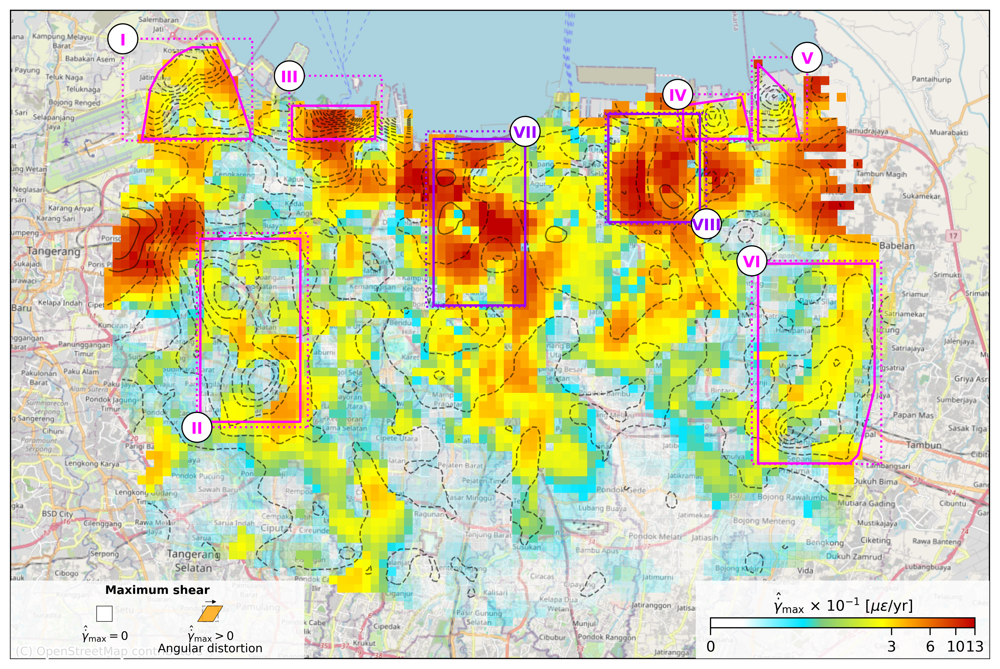

In [16]:
# ============================================================
# --- Manuscript map configurations ---
# ============================================================
# Map of the first strain-rate invariant, I1:
#   strain_type = "areal"
#   color_mode = "field_2sigma"
#
# Map of the maximum engineering shear strain rate, gamma_max:
#   strain_type = "max_shear"
#   color_mode = "piecewise_log"
#   glyphs_on = False

# ============================================================
# --- User selection ---
# ============================================================

# Displayed strain-rate quantity and uncertainty-based fading.
strain_type = "max_shear"          # "areal" or "max_shear"
strain_filter_type = "areal"   # "areal", "max_shear", or "principal"
color_mode = "piecewise_log"    # "absmax", "field_2sigma", "p95",
                               # "logarithmic", or "piecewise_log"

# Map components.
glyphs_on = False
regions_on = True
include_additional_regions = True
contours_on = True
scalebar_on = False
plot_basemap = True
plot_inset = True
glyph_legend = True

# Colorbar placement.
colorbar_pos = "inside"        # "inside" or "outside"

# Statistical display thresholds and opacity.
mask_with_sigma_vel = 2
mask_with_sigma_glyph = 3
mask_with_sigma_rum = 2
weak_alpha = 0.35

# Output.
save_figure = True
output_filename = f"strain_map_{strain_type}_final.png"
figure_dpi = 500

# Use the footprint width recorded in the inversion archive.
RUM_size = float(rum_width)

valid_strain_types = {"areal", "max_shear"}
if strain_type not in valid_strain_types:
    raise ValueError(f"strain_type must be one of {sorted(valid_strain_types)}.")

valid_filter_types = {"areal", "max_shear", "principal"}
if strain_filter_type not in valid_filter_types:
    raise ValueError(
        f"strain_filter_type must be one of {sorted(valid_filter_types)}."
    )

# =================================================
# PRINCIPAL-STRAIN GLYPH DISPLAY OPTIONS
# =================================================
# These options do not change the first glyph-selection step:
# glyph candidates are still selected from RUM velocity significance,
# then one strongest glyph is kept per thinning cell.
#
# 1) Base thinning size:
#    This is the default map-grid size used to avoid plotting every glyph.
glyph_thinning_grid_size = RUM_size * 2.5

# 2) Region-aware thinning:
#    Use smaller thinning cells inside the outlined regions and larger
#    thinning cells outside if you want to emphasize principal directions
#    within the interpreted regions.
#
#    If both values are equal to glyph_thinning_grid_size, region-aware
#    thinning is effectively disabled and the script behaves as before.
glyph_thinning_grid_size_inside_regions = glyph_thinning_grid_size
glyph_thinning_grid_size_outside_regions = glyph_thinning_grid_size

# Example choices:
glyph_thinning_grid_size_inside_regions = RUM_size * 3.0
glyph_thinning_grid_size_outside_regions = RUM_size * 3.0

# Regions used only for region-aware glyph thinning. These match the
# outlined interpretation boxes I-X used later in the plotting workflow.
glyph_region_thinning_boxes = MAIN_REGIONS + ADDITIONAL_REGIONS

# 3) Minimum visible glyph length:
#    After principal strain values are converted into map arrow lengths,
#    this hides the whole glyph if its longest direction is shorter than
#    the threshold. Units are projected-map meters.
#    Set to 0.0 or None to disable.
minimum_glyph_length_m = 0.85 * RUM_size

# 4) Glyph outline style:
#    Each principal-strain arrow is drawn once and receives a Matplotlib
#    path-effect stroke. This replaces the older double-drawing method.
#      epsilon_1: black fill, glyph_e1_outline_color outline
#      epsilon_2: white fill, glyph_e2_outline_color outline
#    glyph_outline_linewidth is in display points, not map meters.
glyph_e1_outline_color = "yellow"
glyph_e2_outline_color = "black"
glyph_outline_linewidth = 2.0

#    Multiplies the final glyph opacity. The statistical mask still decides
#    whether a glyph is visible; this only makes visible glyphs slightly
#    transparent so the map underneath remains readable.
glyph_alpha_factor = 0.65

# 5) Principal-strain glyph legend:
#    If True, draw a reference glyph in the top-right map corner.
#    The reference symbol uses the same strain_scaling as the plotted glyphs,
#    so glyph_legend_value is in the same plotted strain unit as eps_1_hat/eps_2_hat.
#glyph_legend = True
glyph_legend_value = 1.0
glyph_legend_label = rf"{glyph_legend_value:g} {unit_label}"
#    Background style for the legend box.
glyph_legend_facecolor = "white"
glyph_legend_alpha = 0.92
#    Text size for the legend label.
glyph_legend_fontsize = 11
#    0.0 aligns the legend box with the top-right map corner.
#    Increase slightly, e.g. 0.01, to inset it from the frame.
glyph_legend_corner_inset_fraction = 0.0

# 6) Short principal-direction behavior:
#    A glyph can pass the statistical filters but still have one direction
#    whose plotted arrow is so short that the shaft disappears and only the
#    arrowhead remains. Choose how to handle those short directions.
#
#    "none"    -> draw the ordinary arrow regardless of length
#    "skip"    -> do not draw that short direction
#    "bar"     -> draw that short direction as a centered bar without heads
#    "rescale" -> shrink arrow shaft/head dimensions so the arrow remains readable
glyph_short_direction_mode = "skip"  # "none", "skip", "bar", or "rescale"
#    Length threshold, in projected-map meters, below which a single
#    principal direction is considered too short for an ordinary arrow.
glyph_short_direction_threshold_m = 0.45 * RUM_size
#    For short bars, the path-effect outline is scaled down when the bar is
#    very short. This prevents the outline color from visually filling the
#    entire bar. Example: 0.25 keeps at least 25% of glyph_outline_linewidth.
glyph_short_bar_outline_min_factor = 0.10
#    Lowest scale factor allowed when glyph_short_direction_mode="rescale".
#    Example: 0.35 means arrow shaft/head dimensions never shrink below 35%.
glyph_short_rescale_min_factor = 0.35

# 7) Near-uniform extension/compression glyph style:
#    If both principal strains have the same sign AND almost the same
#    magnitude, the glyph represents near-uniform two-direction extension
#    or compaction. In that case, draw both directions as black arrows
#    with a white outline.
#
#    The tolerance is a relative difference:
#      abs(|eps_1_hat| - |eps_2_hat|) / max(|eps_1_hat|, |eps_2_hat|)
#
#    Example:
#      0.25 means the two magnitudes can differ by up to 25%.
glyph_uniform_same_sign_black = True
glyph_uniform_relative_tolerance = 0.25
#    Outline used only for near-uniform extension/compaction glyphs.
glyph_uniform_outline_color = "white"

# 8) Inward-arrow center gap:
#    For contraction arrows, the two arrowheads point toward each other.
#    This value is the extra clear space requested around the glyph center,
#    in projected-map meters. The renderer also adds half of the perpendicular
#    direction's shaft width, so inward arrowheads separate from each other
#    and from the crossing principal direction. Used for map and legend glyphs.
glyph_contraction_center_gap_m = 0.350 * RUM_size

# =================================================
# MAX-SHEAR LOG / SEMILOG COLOR SCALE SETTINGS
# =================================================
# Used only when:
#   strain_type == "max_shear"
#   color_mode == "logarithmic"
#
# The scale is semi-logarithmic:
#   - linear from 0 to linthresh
#   - log-like above linthresh
#
# This is useful when the ordinary linear map is readable up to yellow/orange,
# but the highest gamma_max_hat values saturate too strongly in red.
#
# Choose how to define the linear-to-log transition:
#   "percentile" -> linthresh is computed from the data percentile
#   "value"      -> linthresh is a manually specified value in plotted units
max_shear_log_linthresh_mode = "value"  # "percentile" or "value"
max_shear_log_linthresh_percentile = 85.0
max_shear_log_linthresh_value = 0.1*2 #microstrain/yr

# Choose how to define the upper colorbar limit:
#   "percentile" -> vmax is computed from the data percentile
#   "value"      -> vmax is a manually specified value in plotted units
max_shear_log_vmax_mode = "value"       # "percentile" or "value"
max_shear_log_vmax_percentile = 100.0
max_shear_log_vmax_value = 0.6*2

# =================================================
# MAX-SHEAR PIECEWISE LOG COLOR SCALE SETTINGS
# =================================================
# Used only when:
#   strain_type == "max_shear"
#   color_mode == "piecewise_log"
#
# Interpretation:
#   0 -> max_shear_piecewise_knee is mapped linearly.
#   max_shear_piecewise_knee -> max_shear_piecewise_vmax is log-compressed.
#
# This lets values near the old red/orange threshold remain visually strong,
# while values above that threshold are not all clipped into identical red.

max_shear_piecewise_knee_mode = "value"       # "percentile" or "value"
max_shear_piecewise_knee_percentile = 85.0
max_shear_piecewise_knee_value = 0.2         # plotted units, e.g. microstrain/yr

max_shear_piecewise_vmax_mode = "value"       # "percentile" or "value"
max_shear_piecewise_vmax_percentile = 100.0
max_shear_piecewise_vmax_value = 1.3 #0.8       # plotted units, e.g. microstrain/yr

# Fraction of the colormap used by the linear part.
# Example: 0.85 means 0 -> knee uses 85% of the colorbar,
# and knee -> vmax uses only the final 15%.
max_shear_piecewise_knee_color_fraction = 0.6#0.8

# Controls how strongly the upper tail is compressed.
# Larger values give stronger compression above the knee.
max_shear_piecewise_tail_shape = 3.0

# Clip kriging contour lines to the same FEM/RUM footprint used for plotting.
# This prevents contours from extending outside the supported deformation field.
mask_contours_to_fem_support = True

# contour_support_buffer_m expands/contracts the clipping footprint in meters.
#   0.0  -> exact selected FEM-cell footprint
#   >0   -> slightly expands the contour area, useful if tiny cracks appear
#   <0   -> clips slightly inside the footprint
contour_support_buffer_m = 0.0

# contour_support_simplify_m simplifies the clipping boundary in meters.
#   0.0  -> preserve the exact cell-stepped boundary
#   >0   -> smoother/faster boundary, but too-large values remove detail
contour_support_simplify_m = 0.0

# =================================================
# STRAIN UNIT SCALING
# =================================================
# Raw strain is assumed to be mε/yr.
strain_unit = "micro"                   # "milli", "micro", "pico"

if strain_unit.lower() in ["micro", "μ", "με"]:
    scale = 1e3
    unit_label = r"$\mu\epsilon$/yr"
elif strain_unit.lower() in ["pico", "pε"]:
    scale = 1e6
    unit_label = r"p$\epsilon$/yr"
else:
    scale = 1.0
    unit_label = r"m$\epsilon$/yr"

# =================================================
# PULL STRAIN INVARIANTS & UNCERTAINTIES
# =================================================
eps_1_hat    = derived_quantities["eps_1_hat"]
eps_2_hat    = derived_quantities["eps_2_hat"]
theta_hat = derived_quantities["theta_hat"]

I1_hat = derived_quantities["I1_hat"]
gamma_max_hat  = derived_quantities["gamma_max_hat"]

sigma_eps_1    = derived_quantities["sigma_eps_1"]
sigma_eps_2    = derived_quantities["sigma_eps_2"]
sigma_I1   = derived_quantities["sigma_I1"]
sigma_gamma_max = derived_quantities["sigma_gamma_max"]

# =================================================
# SHEAR LABEL
# =================================================
# label_gamma_max is created in the invariant-computation block.
# It is either:
#   r"$\dot{\gamma}_{\max}$"      for engineering gamma_max_hat
#   r"$\dot{\gamma}_{\max}/2$"    for tensorial gamma_max_hat
label_gamma_max = derived_quantities.get("label_gamma_max", r"$\hat{\dot{\gamma}}_{\max}$")

# =================================================
# FEM SUPPORT MASK
# =================================================
n_elem = len(elements)

if "plot_mask" not in globals():
    plot_mask = np.ones(n_elem, dtype=bool)

plot_mask = np.asarray(plot_mask, dtype=bool)

if plot_mask.shape[0] != n_elem:
    raise ValueError(
        f"plot_mask must have length n_elem={n_elem}, but got {plot_mask.shape[0]}."
    )

valid_mask = plot_mask.copy()

# Remove completely empty numerical cells after applying plot_mask.
eps_val = 1e-12
empty_solution_mask = (
    (np.abs(eps_EE_hat) <= eps_val)
    & (np.abs(eps_NN_hat) <= eps_val)
    & (np.abs(eps_EN_hat) <= eps_val)
    & (sigma_eps_EE == 0)
    & (sigma_eps_NN == 0)
    & (sigma_eps_EN == 0)
)

valid_mask = valid_mask & (~empty_solution_mask)

elem_centers_rum = elem_centers

print(f"FEM elements total        : {n_elem}")
print(f"FEM elements in plot_mask : {plot_mask.sum()}")
print(f"FEM elements plotted      : {valid_mask.sum()}")

# =================================================
# CONTOUR SUPPORT FOOTPRINT
# =================================================
# Contours are clipped to the final FEM plotting support. If plot_mask was
# created by the RUM-envelope code before this script, then valid_mask carries
# that same RUM-supported footprint, plus removal of empty numerical cells.
if mask_contours_to_fem_support:
    contour_support_footprint = build_fem_support_footprint(
        elements=elements,
        node_coords=node_coords,
        support_mask=valid_mask,
        buffer_m=contour_support_buffer_m,
        simplify_m=contour_support_simplify_m,
    )
else:
    contour_support_footprint = None

# =================================================
# SELECT SCALAR FIELD TO PLOT
# =================================================
if strain_type == "areal":
    values_to_plot = I1_hat
    std_to_use = sigma_I1
    cmap_used = "areal_color_r" #"bwr_r" #
    value_scale = scale
    std_scale = scale

elif strain_type == "max_shear":
    values_to_plot = gamma_max_hat
    std_to_use = sigma_gamma_max
    cmap_used = "shear_color" #"Reds" #
    value_scale = scale
    std_scale = scale

else:
    raise ValueError("strain_type must be 'areal' or 'max_shear'")

# =================================================
# SCALE FULL ARRAYS
# =================================================
values_plot_scaled = values_to_plot * value_scale
std_scaled = std_to_use * std_scale

e1_scaled = eps_1_hat * scale
e2_scaled = eps_2_hat * scale
std_e1_scaled = sigma_eps_1 * scale
std_e2_scaled = sigma_eps_2 * scale

dilatation_scaled = I1_hat * scale
shear_inv_scaled = gamma_max_hat * scale

# =================================================
# APPLY plot_mask / valid_mask TO ALL FEM ARRAYS
# =================================================
x_masked = elem_centers_rum[:, 0][valid_mask]
y_masked = elem_centers_rum[:, 1][valid_mask]

values_masked = values_plot_scaled[valid_mask]
std_masked = std_scaled[valid_mask]

e1_masked = e1_scaled[valid_mask]
e2_masked = e2_scaled[valid_mask]
theta_masked = theta_hat[valid_mask]

std_e1_masked = std_e1_scaled[valid_mask]
std_e2_masked = std_e2_scaled[valid_mask]

dilatation_masked = dilatation_scaled[valid_mask]
shear_inv_masked = shear_inv_scaled[valid_mask]

# =================================================
# ALPHA FADING BASED ON SIGMA MASK
# =================================================
if strain_filter_type in ["areal", "max_shear"]:
    std_nonzero = std_masked[std_masked > 0]
else:
    std_nonzero = np.concatenate([
        std_e1_masked[std_e1_masked > 0],
        std_e2_masked[std_e2_masked > 0],
    ])

if std_nonzero.size == 0:
    min_std = np.nan
    alpha_masked = np.ones_like(values_masked)
    print("Warning: no positive standard deviations found; alpha mask disabled.")
else:
    min_std = np.nanpercentile(std_nonzero, 10)
    print(f"RUM fading: Using min_std = {min_std:.3e}")

    if mask_with_sigma_rum is None:
        alpha_masked = np.ones_like(values_masked)
    else:
        if strain_filter_type in ["areal", "max_shear"]:
            std_safe = np.maximum(std_masked, min_std)

            alpha_masked = np.where(
                np.abs(values_masked) > mask_with_sigma_rum * std_safe,
                1.0,
                weak_alpha,
            )
        else:
            std_e1_safe = np.maximum(std_e1_masked, min_std)
            std_e2_safe = np.maximum(std_e2_masked, min_std)

            alpha_masked = np.where(
                (np.abs(e1_masked) > mask_with_sigma_rum * std_e1_safe)
                | (np.abs(e2_masked) > mask_with_sigma_rum * std_e2_safe),
                1.0,
                weak_alpha,
            )

print(
    "Alpha stats:",
    np.nanmin(alpha_masked),
    np.nanmax(alpha_masked),
    np.sum(alpha_masked < 1.0),
)

# =================================================
# FIGURE AND COLOR RANGE
# =================================================
fig, ax = plt.subplots(figsize=(12, 8), dpi=500)

finite_values = values_masked[np.isfinite(values_masked)]

if finite_values.size == 0:
    raise ValueError("No finite values available to plot after masking.")

norm_used = None

if strain_type == "max_shear":
    if color_mode == "field_2sigma":
        vlim = 2 * np.nanstd(finite_values)
        vmin, vmax = 0, vlim

    elif color_mode == "absmax":
        vlim = np.nanmax(finite_values) * 0.75
        vmin, vmax = 0, vlim

    elif color_mode == "p95":
        vlim = np.nanpercentile(finite_values, 95)
        vmin, vmax = 0, vlim

    elif color_mode == "logarithmic":
        positive_max_shear = _positive_values(finite_values)

        max_shear_min = np.nanmin(finite_values)
        max_shear_max = np.nanmax(finite_values)
        max_shear_positive_min = np.nanmin(positive_max_shear)
        max_shear_positive_max = np.nanmax(positive_max_shear)

        linthresh = max_shear_log_scale_value(
            positive_max_shear,
            mode=max_shear_log_linthresh_mode,
            percentile=max_shear_log_linthresh_percentile,
            value=max_shear_log_linthresh_value,
            name="max_shear_log_linthresh",
        )

        vmax = max_shear_log_scale_value(
            positive_max_shear,
            mode=max_shear_log_vmax_mode,
            percentile=max_shear_log_vmax_percentile,
            value=max_shear_log_vmax_value,
            name="max_shear_log_vmax",
        )

        if vmax <= linthresh:
            raise ValueError(
                "For logarithmic max-gamma_max_hat scaling, vmax must be larger than linthresh. "
                f"Got linthresh={linthresh:.6g}, vmax={vmax:.6g}."
            )

        vmin = 0.0

        print("")
        print("Max-shear logarithmic color scaling")
        print(f"Finite max-gamma_max_hat min/max              : {max_shear_min:.6g} / {max_shear_max:.6g} [{unit_label}]")
        print(f"Positive max-gamma_max_hat min/max            : {max_shear_positive_min:.6g} / {max_shear_positive_max:.6g} [{unit_label}]")
        print(f"linthresh mode                        : {max_shear_log_linthresh_mode}")
        print(f"linthresh used                        : {linthresh:.6g} [{unit_label}]")
        print(f"vmax mode                             : {max_shear_log_vmax_mode}")
        print(f"vmax used                             : {vmax:.6g} [{unit_label}]")
        print("Color scale behavior                  : linear from 0 to linthresh, log-like from linthresh to vmax")

        norm_used = SymLogNorm(
            linthresh=linthresh,
            linscale=1.0,
            vmin=vmin,
            vmax=vmax,
            base=10,
        )

    elif color_mode == "piecewise_log":
        positive_max_shear = _positive_values(finite_values)

        max_shear_min = np.nanmin(finite_values)
        max_shear_max = np.nanmax(finite_values)
        max_shear_positive_min = np.nanmin(positive_max_shear)
        max_shear_positive_max = np.nanmax(positive_max_shear)

        knee = max_shear_log_scale_value(
            positive_max_shear,
            mode=max_shear_piecewise_knee_mode,
            percentile=max_shear_piecewise_knee_percentile,
            value=max_shear_piecewise_knee_value,
            name="max_shear_piecewise_knee",
        )

        vmax = max_shear_log_scale_value(
            positive_max_shear,
            mode=max_shear_piecewise_vmax_mode,
            percentile=max_shear_piecewise_vmax_percentile,
            value=max_shear_piecewise_vmax_value,
            name="max_shear_piecewise_vmax",
        )

        if vmax <= knee:
            raise ValueError(
                "For piecewise max-gamma_max_hat scaling, vmax must be larger than knee. "
                f"Got knee={knee:.6g}, vmax={vmax:.6g}."
            )

        vmin = 0.0

        norm_used = make_positive_piecewise_log_norm(
            knee=knee,
            vmax=vmax,
            knee_color_fraction=max_shear_piecewise_knee_color_fraction,
            tail_shape=max_shear_piecewise_tail_shape,
        )

        print("")
        print("Max-shear piecewise-log color scaling")
        print(f"Finite max-gamma_max_hat min/max              : {max_shear_min:.6g} / {max_shear_max:.6g} [{unit_label}]")
        print(f"Positive max-gamma_max_hat min/max            : {max_shear_positive_min:.6g} / {max_shear_positive_max:.6g} [{unit_label}]")
        print(f"knee mode                             : {max_shear_piecewise_knee_mode}")
        print(f"knee used                             : {knee:.6g} [{unit_label}]")
        print(f"knee color fraction                   : {max_shear_piecewise_knee_color_fraction:.3f}")
        print(f"vmax mode                             : {max_shear_piecewise_vmax_mode}")
        print(f"vmax used                             : {vmax:.6g} [{unit_label}]")
        print(f"tail shape                            : {max_shear_piecewise_tail_shape:.3f}")
        print("Color scale behavior                  : linear from 0 to knee, log-compressed from knee to vmax")

    else:
        raise ValueError(
            "color_mode must be 'absmax', 'field_2sigma', 'p95', 'logarithmic', or 'piecewise_log'."
        )

else:
    abs_vals = np.abs(finite_values)

    if color_mode == "absmax":
        vmax = np.nanmax(abs_vals) * 0.75
    elif color_mode == "field_2sigma":
        vmax = 2 * np.nanstd(finite_values)
    elif color_mode == "p95":
        vmax = np.nanpercentile(abs_vals, 95)
    elif color_mode in ["logarithmic", "piecewise_log"]:
        raise ValueError(
            "color_mode='logarithmic' and color_mode='piecewise_log' are currently "
            "supported only for strain_type='max_shear'."
        )
    else:
        raise ValueError(
            "color_mode must be 'absmax', 'field_2sigma', 'p95', or 'logarithmic'."
        )

    vmin = -vmax

# =================================================
# LIMITS FIRST: contextily needs the target map extent
# =================================================
ax.set_aspect("equal", adjustable="datalim")

xlim = (np.nanmin(x_masked) - 2000, np.nanmax(x_masked) + 2000)
ylim = (np.nanmin(y_masked) - 2000, np.nanmax(y_masked) + 2000)

ax.set_xlim(xlim)
ax.set_ylim(ylim)

# =================================================
# BASEMAP BELOW EVERYTHING
# =================================================
if plot_basemap:
    cx.add_basemap(
        ax,
        crs="EPSG:23830",
        source=cx.providers.OpenStreetMap.Mapnik,
        zoom=12,
        zorder=0,
    )

    # Restore limits because contextily can slightly alter them.
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# =================================================
# FEM STRAIN FIELD ABOVE BASEMAP
# =================================================
scatter_kwargs = {
    "x": x_masked,
    "y": y_masked,
    "c": values_masked,
    "s": 37.7,
    "marker": "s",
    "cmap": cmap_used,
    "linewidths": 0,
    "alpha": alpha_masked,
    "zorder": 5,
}

if norm_used is not None:
    scatter_kwargs["norm"] = norm_used
else:
    scatter_kwargs["vmin"] = vmin
    scatter_kwargs["vmax"] = vmax

sc = ax.scatter(**scatter_kwargs)

# =================================================
# CONTOURS ABOVE FEM CELLS
# =================================================
# These contours are intentionally plotted after the FEM scatter and with a
# higher zorder, so they remain visible over the colored FEM cells.
# The kriging grid is masked outside the same FEM/RUM support footprint used
# for the plotted cells, so contour lines do not spill outside the deformation
# field.
if contours_on:
    if mask_contours_to_fem_support:
        mean_kriging_for_contours, _ = mask_contour_grid_to_footprint(
            plot_data["X"],
            plot_data["Y"],
            plot_data["mean_kriging"],
            contour_support_footprint,
        )
    else:
        mean_kriging_for_contours = plot_data["mean_kriging"]

    ax.contour(
        plot_data["X"],
        plot_data["Y"],
        mean_kriging_for_contours,
        levels=20,
        colors="black",
        alpha=0.55,
        linewidths=0.95,
        zorder=6,
    )

# =================================================
# COLORBAR
# =================================================
strain_titles = {
    "areal": r"$\hat{I}_1$",
    "max_shear": label_gamma_max,
}

cbar_min, cbar_max = sc.get_clim()

# Manual legend-box dimensions. The explanatory inset reuses the visible values.
manual_legend_rect_width = 0.38
manual_legend_rect_height = 0.12
manual_legend_facecolor = "white"
manual_legend_edgecolor = "none"
manual_legend_alpha = 0.85
manual_legend_linewidth = 0.0

manual_legend_visible_width = manual_legend_rect_width
manual_legend_visible_height = manual_legend_rect_height

if colorbar_pos == "outside":
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("bottom", size="5%", pad=0.6)
    cbar = plt.colorbar(sc, cax=cax, orientation="horizontal")

elif colorbar_pos == "inside":
    rect_width = manual_legend_rect_width
    rect_height = manual_legend_rect_height
    rect_x = 1.05 + 0.03 - rect_width
    rect_y = 0.00

    # This is the width actually visible inside the map axes.
    manual_legend_visible_width = min(rect_width, max(1.0 - rect_x, 0.0))
    manual_legend_visible_height = rect_height

    ax.add_patch(Rectangle(
        (rect_x, rect_y),
        rect_width,
        rect_height,
        transform=ax.transAxes,
        facecolor=manual_legend_facecolor,
        edgecolor=manual_legend_edgecolor,
        linewidth=manual_legend_linewidth,
        alpha=manual_legend_alpha,
        zorder=30,
    ))

    cax = inset_axes(
        ax,
        width="27%",
        height="1.5%",
        loc="lower right",
        bbox_to_anchor=(0, +0.025, 1, 1),
        bbox_transform=ax.transAxes,
        borderpad=1,
    )
    cbar = plt.colorbar(sc, cax=cax, orientation="horizontal")

else:
    raise ValueError("colorbar_pos must be 'outside' or 'inside'.")

# -----------------------------
# Colorbar ticks and label
# -----------------------------
unit_label_cb = unit_label

if strain_type == "areal":
    n_ticks = 5
    tick_positions = np.linspace(cbar_min, cbar_max, n_ticks)
    tick_labels = [f"{v:.1f}" for v in tick_positions]

    cbar.set_ticks(tick_positions)
    cbar.ax.set_xticklabels(tick_labels)
    cbar.ax.xaxis.set_tick_params(length=5)
    cbar.ax.xaxis.set_label_position("top")

    cbar.set_label(
        rf"{strain_titles[strain_type]} [{unit_label_cb}]",
        labelpad=5,
    )

else:
    tick_positions, tick_labels, exponent = colorbar_integer_ticks(
        cbar_min,
        cbar_max,
        n_inner=3,
    )

    cbar.set_ticks(tick_positions)
    cbar.ax.set_xticklabels(tick_labels)
    cbar.ax.xaxis.set_tick_params(length=5)
    cbar.ax.xaxis.set_label_position("top")

    if exponent == 0:
        cbar.set_label(
            rf"{strain_titles[strain_type]} [{unit_label_cb}]",
            labelpad=5,
        )
    else:
        cbar.set_label(
            rf"{strain_titles[strain_type]} × $10^{{{exponent}}}$ [{unit_label_cb}]",
            labelpad=5,
        )

# =================================================
# EXPLANATORY INSET
# =================================================
# Optional bottom-left explanatory inset. When plot_inset=False,
# no inset is created and the existing map behavior is unchanged.
if plot_inset:
    add_explanatory_inset(
        ax,
        strain_type=strain_type,
        cmap=sc.cmap,
        label_gamma_max=label_gamma_max,
        rect_width=manual_legend_visible_width,
        rect_height=manual_legend_visible_height,
        facecolor=manual_legend_facecolor,
        edgecolor=manual_legend_edgecolor,
        linewidth=manual_legend_linewidth,
        alpha=manual_legend_alpha,
        zorder=31,
    )

# =================================================
# GLYPHS
# =================================================
if glyphs_on:
    # Principal strain 1 arrow geometry, in projected-map meters.
    # epsilon_1 is plotted as the black principal direction.
    shaft_width1, head_width1, head_length1 = 40, 110, 125

    # Principal strain 2 arrow geometry, in projected-map meters.
    # epsilon_2 is plotted as the white principal direction, except for
    # near-uniform extension/compaction glyphs where both directions are black.
    shaft_width2, head_width2, head_length2 = 10, 100, 110

    # Tail offset used for contraction arrows. The opposing arrowhead tips
    # are controlled separately by glyph_contraction_center_gap_m.
    tip_gap1 = head_length1 * 0.6
    tip_gap2 = head_length2 * 0.6

    v_h = np.hypot(public_df["east"], public_df["north"])

    eigvals = np.array([
        np.linalg.eigvals([
            [public_df.loc[i, "var_east"], public_df.loc[i, "covar_en"]],
            [public_df.loc[i, "covar_en"], public_df.loc[i, "var_north"]],
        ])
        for i in range(len(public_df))
    ])

    v_conf = mask_with_sigma_vel * np.sqrt(np.max(eigvals, axis=1)) / 2
    mask_velocity_significant = v_h > v_conf

    print("")
    print(f"Total RUMs: {len(public_df)}")
    print(f"RUMs kept after velocity significance mask: {np.sum(mask_velocity_significant)}")
    print(f"RUMs removed: {len(public_df) - np.sum(mask_velocity_significant)}")

    glyph_mask_fem = np.zeros(n_elem, dtype=bool)
    glyph_mask_fem[rum_to_fe[mask_velocity_significant]] = True

    glyph_mask = valid_mask & glyph_mask_fem
    glyph_idx_in_valid = np.where(glyph_mask[valid_mask])[0]

    x_plot = x_masked[glyph_idx_in_valid]
    y_plot = y_masked[glyph_idx_in_valid]
    e1_plot = e1_masked[glyph_idx_in_valid]
    e2_plot = e2_masked[glyph_idx_in_valid]
    theta_plot = theta_masked[glyph_idx_in_valid]
    std_e1_plot = std_e1_masked[glyph_idx_in_valid]
    std_e2_plot = std_e2_masked[glyph_idx_in_valid]

    if len(x_plot) > 0:
        std_nonzero = np.concatenate([
            std_e1_plot[std_e1_plot > 0],
            std_e2_plot[std_e2_plot > 0],
        ])

        min_std_glyph = np.nanpercentile(std_nonzero, 10)
        eps_glyph = min_std_glyph

        strength = np.maximum(
            np.abs(e1_plot) / np.maximum(std_e1_plot, eps_glyph),
            np.abs(e2_plot) / np.maximum(std_e2_plot, eps_glyph),
        )

        n_glyphs_before_thinning = len(x_plot)

        use_region_aware_thinning = not (
            np.isclose(glyph_thinning_grid_size_inside_regions, glyph_thinning_grid_size)
            and np.isclose(glyph_thinning_grid_size_outside_regions, glyph_thinning_grid_size)
        )

        x_min_thin, y_min_thin = np.min(x_plot), np.min(y_plot)
        inside_glyph_region = _points_inside_rectangular_regions(
            x_plot,
            y_plot,
            glyph_region_thinning_boxes,
        )

        if use_region_aware_thinning:
            thinning_grid_sizes = np.where(
                inside_glyph_region,
                glyph_thinning_grid_size_inside_regions,
                glyph_thinning_grid_size_outside_regions,
            )

            print("")
            print("Region-aware glyph thinning enabled")
            print(f"Glyphs inside outlined regions before thinning : {np.sum(inside_glyph_region)}")
            print(f"Glyphs outside outlined regions before thinning: {np.sum(~inside_glyph_region)}")
            print(f"Inside-region thinning grid                    : {glyph_thinning_grid_size_inside_regions:.1f} m")
            print(f"Outside-region thinning grid                   : {glyph_thinning_grid_size_outside_regions:.1f} m")
        else:
            thinning_grid_sizes = np.full(len(x_plot), glyph_thinning_grid_size, dtype=float)

            print("")
            print("Region-aware glyph thinning disabled")
            print(f"Glyph thinning grid size: {glyph_thinning_grid_size:.1f} m")

        best_in_cell = {}
        for i in range(len(x_plot)):
            grid_size_i = thinning_grid_sizes[i]
            region_group_i = "inside" if inside_glyph_region[i] else "outside"
            x_idx_i = int((x_plot[i] - x_min_thin) // grid_size_i)
            y_idx_i = int((y_plot[i] - y_min_thin) // grid_size_i)

            # The region group is part of the key so inside and outside
            # thinning do not compete for the same retained glyph.
            cell = (region_group_i, x_idx_i, y_idx_i)

            if cell not in best_in_cell or strength[i] > strength[best_in_cell[cell]]:
                best_in_cell[cell] = i

        keep_indices = np.array(list(best_in_cell.values()), dtype=int)

        x_plot = x_plot[keep_indices]
        y_plot = y_plot[keep_indices]
        e1_plot = e1_plot[keep_indices]
        e2_plot = e2_plot[keep_indices]
        theta_plot = theta_plot[keep_indices]
        std_e1_plot = std_e1_plot[keep_indices]
        std_e2_plot = std_e2_plot[keep_indices]

        print(f"Glyphs before thinning: {n_glyphs_before_thinning}")
        print(f"Glyphs after thinning: {len(x_plot)}")
        print(f"Removed by thinning: {n_glyphs_before_thinning - len(x_plot)}")

        # Glyph length scaling:
        # target_cm sets the desired plotted size of the strongest glyphs
        # on the final figure. Larger values make all glyphs longer.
        target_cm = 1.0
        fig_width_cm = fig.get_figwidth() * 2.54
        fig_height_cm = fig.get_figheight() * 2.54

        xdata_per_cm = (xlim[1] - xlim[0]) / fig_width_cm
        ydata_per_cm = (ylim[1] - ylim[0]) / fig_height_cm

        abs_lam = np.concatenate([np.abs(e1_plot), np.abs(e2_plot)])
        mean_top5 = np.nanmean(abs_lam[abs_lam >= np.nanpercentile(abs_lam, 95)])

        strain_scaling = target_cm * min(xdata_per_cm, ydata_per_cm) / mean_top5

        # Final visual boost applied after the automatic scale estimate.
        # Increase for longer glyphs; decrease if glyphs are too dominant.
        strain_scaling *= 1.6#1.2

        std_nonzero = np.concatenate([
            std_e1_plot[std_e1_plot > 0],
            std_e2_plot[std_e2_plot > 0],
        ])
        min_std_glyph = np.nanpercentile(std_nonzero, 40)

        if mask_with_sigma_glyph is None:
            alpha_glyph = np.ones_like(e1_plot)
        else:
            std_safe_e1 = np.maximum(std_e1_plot, min_std_glyph)
            std_safe_e2 = np.maximum(std_e2_plot, min_std_glyph)

            alpha_glyph = np.where(
                (np.abs(e1_plot) > mask_with_sigma_glyph * std_safe_e1)
                | (np.abs(e2_plot) > mask_with_sigma_glyph * std_safe_e2),
                1.0,
                0.0,
            )

        print(f"Glyphs kept after sigma mask: {np.sum(alpha_glyph == 1.0)}")
        print(f"Glyphs removed due to low S/N: {np.sum(alpha_glyph == 0.0)}")

        # Hide glyphs that are statistically selected but too small to read.
        # This is a display-only filter: it does not change the velocity mask,
        # the thinning winner, or the strain significance test above.
        if minimum_glyph_length_m is not None and minimum_glyph_length_m > 0:
            glyph_max_length_m = np.maximum(
                np.abs(e1_plot) * strain_scaling,
                np.abs(e2_plot) * strain_scaling,
            )
            too_short_glyph = glyph_max_length_m < minimum_glyph_length_m
            visible_before_length_filter = np.sum(alpha_glyph == 1.0)

            alpha_glyph = np.where(too_short_glyph, 0.0, alpha_glyph)

            print(f"Minimum visible glyph length: {minimum_glyph_length_m:.1f} m")
            print(f"Glyphs hidden because symbols are too small: {np.sum(too_short_glyph)}")
            print(f"Glyphs visible after length filter: {np.sum(alpha_glyph == 1.0)}")
            print(f"Visible glyphs removed by length filter: {visible_before_length_filter - np.sum(alpha_glyph == 1.0)}")
        else:
            print("Minimum visible glyph length filter disabled")

        for k in range(len(x_plot)):
            _draw_principal_glyph(
                ax,
                x_plot[k],
                y_plot[k],
                e1_plot[k],
                e2_plot[k],
                theta_plot[k],
                alpha_glyph[k],
                strain_scaling,
                zorder=12,
            )

        _add_principal_glyph_legend(
            ax,
            ref_value=glyph_legend_value,
            strain_scaling_i=strain_scaling,
        )

# =================================================
# REGIONS AND STRAIN SUMMARY
# =================================================
if regions_on:
    plot_regions_with_strain_summary(
        ax,
        E_rum=x_masked,
        N_rum=y_masked,
        eps_1_hat=e1_masked,
        eps_2_hat=e2_masked,
        I1_hat=dilatation_masked,
        gamma_max_hat=shear_inv_masked,
        strain_type=strain_type,
        regions_proj=None,
        label_offset=0,
        color=MAIN_REGION_COLOR,
        include_additional_regions=include_additional_regions,
    )

# =================================================
# SCALE BAR
# =================================================
if scalebar_on:
    scalebar_length_km = 10
    scalebar_length_m = scalebar_length_km * 1000

    x_center = 0.5 * (ax.get_xlim()[0] + ax.get_xlim()[1])
    y_min_axis = ax.get_ylim()[0]

    bar_height = (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.01
    segment_length = scalebar_length_m / 5
    bar_y = y_min_axis + bar_height * 3

    bg_width = scalebar_length_m * 1.2
    bg_height = bar_height * 6
    bg_x = x_center - bg_width / 2
    bg_y = bar_y - bg_height / 2

    ax.add_patch(Rectangle(
        (bg_x, bg_y),
        bg_width,
        bg_height,
        facecolor="white",
        edgecolor="none",
        alpha=0.85,
        zorder=20,
    ))

    for i in range(5):
        ax.add_patch(Rectangle(
            (x_center - scalebar_length_m / 2 + i * segment_length, bar_y - 500),
            segment_length,
            bar_height,
            facecolor="black" if i % 2 == 0 else "white",
            edgecolor="black",
            linewidth=0.8,
            zorder=21,
        ))

    ax.text(
        x_center - scalebar_length_m / 2,
        bar_y + bar_height * 1.8 - 500,
        "0",
        fontsize=10,
        ha="center",
        va="bottom",
        color="black",
        zorder=22,
    )

    ax.text(
        x_center + scalebar_length_m / 2 - 100,
        bar_y + bar_height * 1.8 - 500,
        f"{scalebar_length_km} km",
        fontsize=10,
        ha="center",
        va="bottom",
        color="black",
        zorder=22,
    )

# =================================================
# FINISH
# =================================================
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])

if save_figure:
    output_path = FIGURES_DIR / output_filename
    fig.savefig(output_path, dpi=figure_dpi, bbox_inches="tight")
    print(f"Figure saved to {output_path}")

# Display the completed figure as a notebook output.
display(fig)
plt.close(fig)
